# Named Entity Recognition in Kazakh News (KazNERD)

Final project for *Programming for Data Analysis and Database* (MSc Applied Artificial Intelligence,
Astana IT University) — Cluster 2: Text Analytics & NLP.

This notebook holds the whole project in one place. It finds persons, organisations, locations and 22 other
entity classes in Kazakh news sentences:

1. **Data** — streaming 1.3M token rows into a DataFrame with compact dtypes, then Parquet / CSV
2. **Preprocessing** — tokenization, stop words, Kazakh stemmer vs lemmatizer
3. **EDA** — word / n-gram frequencies, entity statistics, word clouds
4. **SQLite database** — corpus, entities, keywords, model results
5. **Models** — baseline, SGD on BoW / TF-IDF / Word2Vec, CRF, evaluated with seqeval
6. **Analytical SQL queries** (14 queries)
7. **Benchmarks** — CSV vs Parquet, dtypes, Pandas vs SQL
8. **Error analysis** and confusion matrix
9. **Recognising entities in your own text**
10. **Results summary**
11. *(optional, GPU)* fine-tuning XLM-RoBERTa

Run the cells from top to bottom. A full run takes about 30 min on a laptop CPU, most of it CRF training.
Use the `TRAIN_MODELS` setting in the configuration cell to skip slow models.

**Data:** [KazNERD](https://github.com/IS2AI/KazNERD) (Yeshpanov et al., LREC 2022, CC BY 4.0) and
[UD Kazakh-KTB](https://github.com/UniversalDependencies/UD_Kazakh-KTB) (CC BY-SA 4.0) for gold lemmas.
Files missing from `data/` are downloaded automatically.

## 0. Setup: imports and configuration

In [1]:
# If needed: !pip install numpy pandas pyarrow scipy scikit-learn nltk gensim python-crfsuite seqeval matplotlib wordcloud psutil joblib
import json
import os
import random
import re
import sqlite3
import statistics
import threading
import time
import urllib.request
from collections import Counter, defaultdict
from datetime import datetime
from functools import lru_cache
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pycrfsuite
from matplotlib.colors import LinearSegmentedColormap
from nltk.stem.api import StemmerI
from nltk.util import ngrams
from scipy import sparse
from seqeval.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

%matplotlib inline
pd.set_option("display.max_colwidth", 80)

In [2]:
# --- directories (the notebook lives in the project root) ---------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"            # original KazNERD CoNLL files
UD_DIR = DATA_DIR / "ud_kazakh"       # UD Kazakh-KTB (gold lemmas)
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
RESULTS_DIR = REPORTS_DIR / "results"
DOCS_DIR = ROOT / "docs"

DB_PATH = DATA_DIR / "kaznerd.db"
TOKENS_PARQUET = PROCESSED_DIR / "tokens.parquet"
TOKENS_CSV = PROCESSED_DIR / "tokens.csv"
STOPWORDS_FILE = DATA_DIR / "stopwords_kk.txt"
COMPARISON_CSV = RESULTS_DIR / "model_comparison.csv"

# --- data sources -------------------------------------------------------------
SPLITS = ("train", "valid", "test")
KAZNERD_URL = "https://raw.githubusercontent.com/IS2AI/KazNERD/main/KazNERD/IOB2_{split}.txt"
UD_URLS = {
    "train": "https://raw.githubusercontent.com/UniversalDependencies/UD_Kazakh-KTB/master/kk_ktb-ud-train.conllu",
    "test": "https://raw.githubusercontent.com/UniversalDependencies/UD_Kazakh-KTB/master/kk_ktb-ud-test.conllu",
}

# --- experiment settings ------------------------------------------------------
SEED = 42
CSV_CHUNKSIZE = 200_000           # rows per chunk when reading CSV / inserting into SQLite
LINEAR_TRAIN_SENTENCES = 30_000   # subsample for BoW / TF-IDF / Word2Vec taggers (memory bound)
CRF_MAX_ITERATIONS = 100
CRF_C1, CRF_C2 = 0.1, 0.1
W2V_DIM = 100
W2V_WINDOW = 5
W2V_EPOCHS = 10

# models trained in section 5 (remove names to skip them; CRF takes ~17 min on CPU)
TRAIN_MODELS = ["baseline_lookup", "sgd_bow", "sgd_tfidf", "sgd_word2vec", "crf"]
RUN_TRANSFORMER = False           # section 11, needs a CUDA GPU

# Short English descriptions of the 25 KazNERD classes (from the annotation guidelines)
ENTITY_TYPES = {
    "ADAGE": "Proverbs, sayings and idioms",
    "ART": "Titles of works of art, books, songs, films",
    "CARDINAL": "Numerals that are not another numeric type",
    "CONTACT": "Addresses, phone numbers, e-mails, URLs",
    "DATE": "Absolute or relative dates and periods",
    "DISEASE": "Diseases and medical conditions",
    "EVENT": "Named events: wars, festivals, sports events",
    "FACILITY": "Buildings, airports, roads, bridges",
    "GPE": "Geo-political entities: countries, cities, regions",
    "LANGUAGE": "Named languages",
    "LAW": "Named laws, codes, treaties, conventions",
    "LOCATION": "Non-GPE locations: rivers, mountains, districts",
    "MISCELLANEOUS": "Other named entities",
    "MONEY": "Monetary values with unit",
    "NON_HUMAN": "Named animals and other non-human beings",
    "NORP": "Nationalities, religious or political groups",
    "ORDINAL": "Ordinal numbers",
    "ORGANISATION": "Companies, agencies, institutions",
    "PERCENTAGE": "Percentages",
    "PERSON": "People, including fictional",
    "POSITION": "Job titles and positions",
    "PRODUCT": "Objects, vehicles, foods, brands",
    "PROJECT": "Named projects, programmes, initiatives",
    "QUANTITY": "Measurements: weight, distance, area",
    "TIME": "Times shorter than a day",
}

### Shared helpers: directories, resource monitor, JSON, IOB2 spans, chart style

In [3]:
def ensure_dirs():
    """Create every output directory used by the project."""
    for d in (DATA_DIR, RAW_DIR, UD_DIR, PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, RESULTS_DIR, DOCS_DIR):
        Path(d).mkdir(parents=True, exist_ok=True)


class ResourceMonitor:
    """Context manager measuring wall time and peak RSS growth of the process.

    A background thread samples the resident set size, so memory allocated by
    C extensions (crfsuite, numpy, pyarrow) is counted too — unlike tracemalloc.
    """

    def __init__(self, interval=0.05):
        self.interval = interval
        self.seconds = 0.0
        self.peak_mb = 0.0
        self._proc = psutil.Process(os.getpid())
        self._stop = threading.Event()

    def _sample(self):
        while not self._stop.is_set():
            rss = self._proc.memory_info().rss
            self._peak = max(self._peak, rss)
            time.sleep(self.interval)

    def __enter__(self):
        self._start_rss = self._proc.memory_info().rss
        self._peak = self._start_rss
        self._thread = threading.Thread(target=self._sample, daemon=True)
        self._thread.start()
        self._t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self._t0
        self._stop.set()
        self._thread.join()
        self._peak = max(self._peak, self._proc.memory_info().rss)
        self.peak_mb = (self._peak - self._start_rss) / 2 ** 20
        return False


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=float)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def print_header(text):
    print("\n" + "=" * 70 + f"\n{text}\n" + "=" * 70)


def get_spans(tags):
    """Convert an IOB2 tag sequence into (type, start, end_exclusive) spans.

    Follows conlleval/seqeval leniency: an I- tag that does not continue an
    entity of the same type starts a new entity.
    """
    spans = []
    cur_type, start = None, None
    for i, tag in enumerate(list(tags) + ["O"]):
        if tag == "O" or tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != cur_type):
            if cur_type is not None:
                spans.append((cur_type, start, i))
                cur_type, start = None, None
            if tag != "O":
                cur_type, start = tag[2:], i
    return spans


def span_text(tokens, start, end):
    return " ".join(tokens[start:end])


ensure_dirs()

In [4]:
# --- chart style and reusable chart helpers (figures are shown inline and saved as PNG) ---
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE_RAMP = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
TEXT_CMAP = LinearSegmentedColormap.from_list("text_blue", BLUE_RAMP[3:])  # readable on light surface
FONT_PATH = matplotlib.get_data_path() + "/fonts/ttf/DejaVuSans.ttf"


def setup_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "font.family": "DejaVu Sans", "font.size": 10,
        "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
        "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    })


def save_and_show(fig, path, dpi=150, show=True):
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


def barh(labels, values, title, path, xlabel="", color=SERIES[0], fmt="{:,.0f}", figsize=(8, 6), show=True):
    """Horizontal bar chart, largest on top, with value labels at bar ends."""
    setup_style()
    fig, ax = plt.subplots(figsize=figsize)
    labels, values = list(labels)[::-1], list(values)[::-1]
    bars = ax.barh(labels, values, color=color, height=0.7)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    vmax = max(values) if values else 1
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.01, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=8, color=INK_2)
    ax.set_xlim(0, vmax * 1.12)
    fig.tight_layout()
    save_and_show(fig, path, show=show)


def grouped_bars(categories, series, title, path, ylabel="", ylim=None, fmt="{:.3f}", show=True):
    """Grouped vertical bars. `series` is {name: [values per category]} (<= 8 series)."""
    setup_style()
    n = len(series)
    width = 0.8 / n
    fig, ax = plt.subplots(figsize=(max(8, len(categories) * 1.4), 5))
    for i, (name, vals) in enumerate(series.items()):
        xs = [j + (i - (n - 1) / 2) * width for j in range(len(categories))]
        bars = ax.bar(xs, vals, width=width * 0.92, color=SERIES[i % len(SERIES)], label=name)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v),
                    ha="center", va="bottom", fontsize=7, color=INK_2)
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=15, ha="right")
    ax.grid(axis="x", visible=False)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False, ncol=min(n, 3), loc="upper left", bbox_to_anchor=(0, -0.22))
    fig.tight_layout()
    save_and_show(fig, path, show=show)

## 1. Data: CoNLL → optimised DataFrame → Parquet + CSV

* The raw CoNLL files are streamed line by line, never read whole.
* All tokens go into one DataFrame with compact dtypes (category / int32 / int16 / pyarrow string).
* The table is saved as Parquet (main format) and CSV (used in the format benchmark).
* Tokens are grouped back into sentences for the models.

In [5]:
def ensure_raw_data():
    """Download any missing KazNERD split from GitHub. Returns the list of local paths."""
    paths = []
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for split in SPLITS:
        path = RAW_DIR / f"IOB2_{split}.txt"
        if not path.exists():
            url = KAZNERD_URL.format(split=split)
            print(f"Downloading {url} ...")
            try:
                urllib.request.urlretrieve(url, path)
            except OSError as exc:  # network errors, HTTP errors (URLError is an OSError)
                raise FileNotFoundError(
                    f"{path.name} is missing and could not be downloaded ({exc}). "
                    f"Download it manually from https://github.com/IS2AI/KazNERD into {RAW_DIR}"
                ) from exc
        paths.append(path)
    return paths


def read_conll(path):
    """Yield (tokens, tags) for every sentence of a CoNLL file (blank-line separated)."""
    tokens, tags = [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if tokens:
                    yield tokens, tags
                    tokens, tags = [], []
                continue
            token, _, tag = line.rpartition(" ")
            tokens.append(token)
            tags.append(tag)
    if tokens:
        yield tokens, tags


def build_token_frame(optimize=True):
    """Parse all splits into one DataFrame: sentence_id, split, position, token, tag."""
    ensure_raw_data()
    sent_ids, splits, positions, tokens, tags = [], [], [], [], []
    sid = 0
    for split in SPLITS:
        for toks, tgs in read_conll(RAW_DIR / f"IOB2_{split}.txt"):
            n = len(toks)
            sent_ids.extend([sid] * n)
            splits.extend([split] * n)
            positions.extend(range(n))
            tokens.extend(toks)
            tags.extend(tgs)
            sid += 1
    df = pd.DataFrame({"sentence_id": sent_ids, "split": splits, "position": positions,
                       "token": tokens, "tag": tags})
    return optimize_dtypes(df) if optimize else df


def optimize_dtypes(df):
    """Downcast integers and turn low-cardinality strings into categoricals."""
    df = df.copy()
    df["sentence_id"] = df["sentence_id"].astype(np.int32)
    df["position"] = df["position"].astype(np.int16)
    df["split"] = df["split"].astype("category")
    df["tag"] = df["tag"].astype("category")
    df["token"] = df["token"].astype("string[pyarrow]")
    return df


def memory_mb(df):
    return df.memory_usage(deep=True).sum() / 2 ** 20


def save_tokens(df):
    """Write Parquet (columnar, compressed) and CSV copies of the token table."""
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    df.to_parquet(TOKENS_PARQUET, index=False, compression="snappy")
    df.to_csv(TOKENS_CSV, index=False)


def load_tokens(fmt="parquet", columns=None):
    """Load the token table; raises FileNotFoundError with a hint if section 1 was not run."""
    path = TOKENS_PARQUET if fmt == "parquet" else TOKENS_CSV
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found — run section 1 (Prepare data) first.")
    if fmt == "parquet":
        return pd.read_parquet(path, columns=columns)
    return pd.read_csv(path, usecols=columns, keep_default_na=False)


def tag_counts_chunked(path=None, chunksize=CSV_CHUNKSIZE):
    """Count tags in the CSV without loading it whole — demonstrates chunked processing."""
    path = path or TOKENS_CSV
    total = pd.Series(dtype="int64")
    n_chunks = 0
    for chunk in pd.read_csv(path, usecols=["tag"], chunksize=chunksize, dtype={"tag": "category"}):
        total = total.add(chunk["tag"].value_counts(), fill_value=0)
        n_chunks += 1
    return total.astype("int64").sort_values(ascending=False), n_chunks


def to_sentences(df):
    """Group the (sorted) token frame into {split: [(sentence_id, tokens, tags), ...]}."""
    result = {}
    for split in SPLITS:
        part = df[df["split"] == split]
        ids = part["sentence_id"].to_numpy()
        toks = part["token"].astype(str).to_numpy()
        tags = part["tag"].astype(str).to_numpy()
        bounds = np.flatnonzero(np.diff(ids)) + 1
        starts = np.concatenate(([0], bounds))
        ends = np.concatenate((bounds, [len(ids)]))
        result[split] = [(int(ids[s]), list(toks[s:e]), list(tags[s:e]))
                         for s, e in zip(starts, ends)]
    return result


def load_sentences():
    return to_sentences(load_tokens("parquet"))

In [6]:
print_header("1. Prepare data: CoNLL -> optimised DataFrame -> Parquet + CSV")
with ResourceMonitor() as mon:
    tokens_df = build_token_frame()
    save_tokens(tokens_df)
data_summary = {
    "rows": len(tokens_df), "sentences": int(tokens_df["sentence_id"].nunique()),
    "rows_per_split": tokens_df["split"].value_counts().reindex(SPLITS).to_dict(),
    "tags": int(tokens_df["tag"].nunique()), "in_memory_mb": memory_mb(tokens_df),
    "seconds": mon.seconds,
}
save_json(data_summary, RESULTS_DIR / "data_summary.json")
print(f"{data_summary['rows']:,} token rows, {data_summary['sentences']:,} sentences, {data_summary['tags']} tags; "
      f"{data_summary['in_memory_mb']:.1f} MB in memory; {mon.seconds:.1f} s")
print(f"Saved {TOKENS_PARQUET.name} and {TOKENS_CSV.name} in {PROCESSED_DIR}")
tokens_df.head(10)


1. Prepare data: CoNLL -> optimised DataFrame -> Parquet + CSV


1,302,352 token rows, 112,702 sentences, 51 tags; 33.2 MB in memory; 2.4 s
Saved tokens.parquet and tokens.csv in C:\Users\amirk\PycharmProjects\kaznerd-ner\data\processed


,sentence_id,split,position,token,tag
0,0,train,0,Еуразиялық,B-LAW
1,0,train,1,экономикалық,I-LAW
2,0,train,2,одақ,I-LAW
3,0,train,3,туралы,I-LAW
4,0,train,4,шартқа,I-LAW
5,0,train,5,қол,O
6,0,train,6,қойылған,O
7,0,train,7,күн,O
8,0,train,8,.,O
9,1,train,0,Ол,O


In [7]:
tokens_df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1302352 entries, 0 to 1302351
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype   
---  ------       --------------    -----   
 0   sentence_id  1302352 non-null  int32   
 1   split        1302352 non-null  category
 2   position     1302352 non-null  int16   
 3   token        1302352 non-null  string  
 4   tag          1302352 non-null  category
dtypes: category(2), int16(1), int32(1), string(1)
memory usage: 33.2 MB


In [8]:
sentences = to_sentences(tokens_df)
{split: len(s) for split, s in sentences.items()}

{'train': 90228, 'valid': 11167, 'test': 11307}

## 2. Preprocessing: tokenization, stop words, stemming, lemmatization

Neither NLTK nor spaCy has a Kazakh stemmer or lemmatizer, so the project uses:
* **KazakhSuffixStemmer** — a rule-based suffix stripper written as an NLTK `StemmerI`,
* **SuffixLemmatizer** — a data-driven lemmatizer that learns "strip / append" suffix rules from the gold
  lemmas of the UD Kazakh-KTB treebank,
* *(optional)* Stanza's neural Kazakh lemmatizer, if it is installed.

All of them are evaluated against held-out UD gold lemmas in `compare_normalizers()`.

In [9]:
TOKEN_RE = re.compile(r"\d+(?:[.,]\d+)*(?:-\w+)?|\w+(?:-\w+)*|[^\w\s]", re.UNICODE)
SENT_RE = re.compile(r"(?<=[.!?])\s+")
KK_VOWELS = set("аәеёиоөуұүыіэюя")


def split_sentences(text):
    return [s for s in SENT_RE.split(text.strip()) if s]


def tokenize(text):
    """Regex word tokenizer matching KazNERD conventions (punctuation is a separate token,
    hyphenated words and numbers with suffixes such as '55-ші' stay whole)."""
    return TOKEN_RE.findall(text)


def is_word(token):
    return any(ch.isalpha() for ch in token)


def load_stopwords():
    """Kazakh stop words from NLTK; falls back to the bundled copy if the corpus is missing."""
    try:
        from nltk.corpus import stopwords
        words = set(stopwords.words("kazakh"))
    except LookupError:
        try:
            import nltk
            nltk.download("stopwords", quiet=True)
            from nltk.corpus import stopwords
            words = set(stopwords.words("kazakh"))
        except Exception:
            words = set(Path(STOPWORDS_FILE).read_text(encoding="utf-8").split())
    return words

In [10]:
_SUFFIXES = """
ының інің сының сінің ындағы індегі ндағы ндегі дағы дегі тағы тегі
ымыз іміз ыңыз іңіз мыз міз быз біз пыз піз ңыз ңіз
ның нің дың дің тың тің
ға ге қа ке на не
ны ні ды ді ты ті
нда нде да де та те
ндан нден нан нен дан ден тан тен
менен мен бен пен
лар лер дар дер тар тер
ым ім ың ің сы сі ы і
мын мін бын бін пын пін сың сің сыз сіз
ған ген қан кен атын етін йтын йтін ады еді йды йді
ып іп мақ мек бақ бек пақ пек уда уде уы уі
""".split()
SUFFIXES = sorted(set(_SUFFIXES), key=len, reverse=True)


class KazakhSuffixStemmer(StemmerI):
    """Greedy longest-suffix stripping, repeated up to `max_passes` times.

    Guards against over-stemming: the remaining stem must keep >= `min_stem`
    characters (>= min_stem + 1 for one-letter suffixes) and contain a vowel.
    """

    def __init__(self, min_stem=3, max_passes=3):
        self.min_stem = min_stem
        self.max_passes = max_passes

    def stem(self, token):
        word = token.lower()
        if not word.isalpha():
            return word
        for _ in range(self.max_passes):
            for suf in SUFFIXES:
                if word.endswith(suf):
                    stem = word[: -len(suf)]
                    need = self.min_stem + (1 if len(suf) == 1 else 0)
                    if len(stem) >= need and KK_VOWELS & set(stem):
                        word = stem
                        break
            else:
                break
        return word

In [11]:
def ensure_ud_data():
    UD_DIR.mkdir(parents=True, exist_ok=True)
    paths = []
    for split, url in UD_URLS.items():
        path = UD_DIR / Path(url).name
        if not path.exists():
            try:
                urllib.request.urlretrieve(url, path)
            except OSError as exc:
                raise FileNotFoundError(f"Cannot download UD Kazakh-KTB ({exc}); "
                                        f"place {path.name} into {UD_DIR}") from exc
        paths.append(path)
    return paths


def read_conllu(path):
    """Return sentences as lists of (form, lemma, upos) from a CoNLL-U file."""
    sents, cur = [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if cur:
                    sents.append(cur)
                    cur = []
                continue
            if line.startswith("#"):
                continue
            cols = line.split("\t")
            if "-" in cols[0] or "." in cols[0]:   # multi-word / empty nodes
                continue
            cur.append((cols[1], cols[2], cols[3]))
    if cur:
        sents.append(cur)
    return sents


def load_ud_split(test_share=0.2, seed=SEED):
    sents = []
    for path in ensure_ud_data():
        sents.extend(read_conllu(path))
    rng = random.Random(seed)
    rng.shuffle(sents)
    cut = int(len(sents) * (1 - test_share))
    return sents[:cut], sents[cut:]


class SuffixLemmatizer:
    """Learns (strip, append) edit rules keyed by word endings from gold (form, lemma) pairs.

    Prediction: exact-form lookup first; otherwise the rule attached to the longest
    known word ending (seen at least `min_count` times) is applied.
    """

    def __init__(self, max_context=3, min_count=2):
        self.max_context = max_context
        self.min_count = min_count
        self.lexicon = {}
        self.rules = {}

    def fit(self, pairs):
        lex = defaultdict(Counter)
        rules = defaultdict(Counter)
        for form, lemma in pairs:
            f, l = form.lower(), lemma.lower()
            if not f.isalpha():
                continue
            lex[f][l] += 1
            p = 0
            while p < min(len(f), len(l)) and f[p] == l[p]:
                p += 1
            strip, add = f[p:], l[p:]
            for k in range(max(len(strip), 1), min(len(f), len(strip) + self.max_context) + 1):
                rules[f[-k:]][(len(strip), add)] += 1
        self.lexicon = {f: c.most_common(1)[0][0] for f, c in lex.items()}
        self.rules = {k: c.most_common(1)[0] for k, c in rules.items()}
        self.max_key = max((len(k) for k in self.rules), default=0)
        return self

    def lemmatize(self, token):
        f = token.lower()
        if not f.isalpha():
            return f
        if f in self.lexicon:
            return self.lexicon[f]
        for k in range(min(self.max_key, len(f) - 1), 0, -1):
            hit = self.rules.get(f[-k:])
            if hit and hit[1] >= self.min_count:
                (n_strip, add), _ = hit
                if len(f) - n_strip >= 2:
                    return f[: len(f) - n_strip] + add
        return f


def stanza_lemmatizer():
    """Return a token->lemma function backed by Stanza's Kazakh model, or None if unavailable."""
    try:
        import logging
        import stanza
        logging.getLogger("stanza").setLevel(logging.CRITICAL)
        nlp = stanza.Pipeline("kk", processors="tokenize,lemma", tokenize_pretokenized=True,
                              download_method=None, logging_level="CRITICAL")
    except Exception:
        return None

    def lemmatize_batch(tokens):
        doc = nlp([list(tokens)])
        return [w.lemma or w.text for w in doc.sentences[0].words]
    return lemmatize_batch


_default_stemmer = KazakhSuffixStemmer()
_default_lemmatizer = None


def get_lemmatizer():
    """Train (once) the suffix lemmatizer on the UD training part and cache it."""
    global _default_lemmatizer
    if _default_lemmatizer is None:
        ud_train, _ = load_ud_split()
        _default_lemmatizer = SuffixLemmatizer().fit((f, l) for s in ud_train for f, l, _ in s)
    return _default_lemmatizer


def stem(token):
    return _default_stemmer.stem(token)


def compare_normalizers(kaznerd_tokens):
    """Stemming vs lemmatization: accuracy against held-out UD gold lemmas,
    vocabulary reduction on KazNERD and speed. Returns a DataFrame."""
    ud_train, ud_test = load_ud_split()
    lemmatizer = SuffixLemmatizer().fit((f, l) for s in ud_train for f, l, _ in s)
    stemmer = KazakhSuffixStemmer()
    train_forms = {f.lower() for s in ud_train for f, _, _ in s}
    gold = [(f, l.lower()) for s in ud_test for f, l, _ in s if f.isalpha()]

    methods = {
        "identity (lowercase)": str.lower,
        "suffix stemmer (rule-based)": stemmer.stem,
        "suffix lemmatizer (UD-trained)": lemmatizer.lemmatize,
    }
    stanza_fn = stanza_lemmatizer()
    if stanza_fn is not None:
        methods["stanza lemmatizer (neural)"] = lambda t: stanza_fn([t])[0].lower()

    words = [t for t in kaznerd_tokens if is_word(t)]
    unique_words = sorted({w.lower() for w in words})
    rows = []
    for name, fn in methods.items():
        preds = [fn(f) for f, _ in gold]
        correct = [p == l for p, (_, l) in zip(preds, gold)]
        oov = [c for c, (f, _) in zip(correct, gold) if f.lower() not in train_forms]
        t0 = time.perf_counter()
        sample = unique_words if "stanza" not in name else unique_words[:2000]
        vocab = {fn(w) for w in sample}
        secs = time.perf_counter() - t0
        rows.append({
            "method": name,
            "ud_accuracy": sum(correct) / len(correct),
            "ud_oov_accuracy": sum(oov) / max(len(oov), 1),
            "kaznerd_vocab": len(vocab) if "stanza" not in name else None,
            "vocab_reduction_pct": 100 * (1 - len(vocab) / len(sample)),
            "ms_per_1k_words": 1000 * secs / len(sample) * 1000,
        })
    df = pd.DataFrame(rows)
    df.attrs["ud_test_tokens"] = len(gold)
    df.attrs["ud_test_oov"] = sum(1 for f, _ in gold if f.lower() not in train_forms)
    return df

In [12]:
# quick look at the preprocessing tools
demo = "Қасым-Жомарт Тоқаев 2024 жылғы 15 наурызда Астанада Ұлттық банктің төрағасымен кездесті."
demo_tokens = tokenize(demo)
stop = load_stopwords()
pd.DataFrame({"token": demo_tokens,
              "stop word": [t.lower() in stop for t in demo_tokens],
              "stem": [stem(t) for t in demo_tokens],
              "lemma": [get_lemmatizer().lemmatize(t) for t in demo_tokens]})

,token,stop word,stem,lemma
0,Қасым-Жомарт,False,қасым-жомарт,қасым-жомарт
1,Тоқаев,False,тоқаев,тоқаев
2,2024,False,2024,2024
3,жылғы,False,жылғ,жылғы
4,15,False,15,15
5,наурызда,False,наурыз,наурыз
6,Астанада,False,аста,астана
7,Ұлттық,False,ұлттық,ұлттық
8,банктің,False,банк,банк
9,төрағасымен,False,төра,төраға


## 3. Exploratory analysis: frequencies, n-grams, entities, word clouds

In [13]:
def token_frequencies(sents, stopwords=None, lowercase=True, words_only=True):
    """Counter of tokens over [(sid, tokens, tags)], optionally without stop words / punctuation."""
    counts = Counter()
    for _, tokens, _ in sents:
        for t in tokens:
            if words_only and not is_word(t):
                continue
            w = t.lower() if lowercase else t
            if stopwords and w in stopwords:
                continue
            counts[w] += 1
    return counts


def ngram_frequencies(sents, n, stopwords=None):
    """Counter of word n-grams; n-grams containing punctuation or stop words are skipped."""
    counts = Counter()
    for _, tokens, _ in sents:
        words = [t.lower() for t in tokens]
        for gram in ngrams(words, n):
            if all(is_word(w) and not (stopwords and w in stopwords) for w in gram):
                counts[" ".join(gram)] += 1
    return counts


def entity_mentions(sents):
    """DataFrame {sentence_id, type, text, length} for every gold entity."""
    rows = []
    for sid, tokens, tags in sents:
        for etype, s, e in get_spans(tags):
            rows.append({"sentence_id": sid, "type": etype, "text": span_text(tokens, s, e), "length": e - s})
    return pd.DataFrame(rows)


def context_keywords(sents, stopwords, window=3, top_k=15):
    """TF-IDF keywords of the words around each entity type (one 'document' per type).

    Answers: which words typically signal a PERSON, a POSITION, a DATE...?"""
    docs = {t: [] for t in ENTITY_TYPES}
    for _, tokens, tags in sents:
        low = [t.lower() for t in tokens]
        for etype, s, e in get_spans(tags):
            ctx = low[max(0, s - window):s] + low[e:e + window]
            docs[etype].extend(w for w in ctx if w.isalpha() and w not in stopwords)
    types = [t for t in docs if docs[t]]
    vec = TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True, min_df=1)
    mat = vec.fit_transform([" ".join(docs[t]) for t in types])
    vocab = vec.get_feature_names_out()
    rows = []
    for i, t in enumerate(types):
        row = mat[i].toarray().ravel()
        for rank, j in enumerate(row.argsort()[::-1][:top_k], 1):
            rows.append({"type_code": t, "rank": rank, "term": vocab[j], "score": float(row[j])})
    return pd.DataFrame(rows)


def make_wordclouds(mentions, path, types=("PERSON", "GPE", "ORGANISATION", "POSITION")):
    from wordcloud import WordCloud
    setup_style()
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, etype in zip(axes.ravel(), types):
        freqs = Counter(mentions.loc[mentions["type"] == etype, "text"])
        wc = WordCloud(width=800, height=450, background_color=SURFACE, font_path=FONT_PATH,
                       colormap=TEXT_CMAP, max_words=80, prefer_horizontal=0.95, random_state=SEED)
        wc.generate_from_frequencies(dict(freqs.most_common(300)))
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(etype)
        ax.axis("off")
    fig.tight_layout()
    save_and_show(fig, path, dpi=130)


def plot_sentence_lengths(sents, path):
    setup_style()
    lengths = [len(t) for _, t, _ in sents]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(lengths, bins=range(0, 61, 2), color=SERIES[0], edgecolor=SURFACE)
    ax.set_title("Sentence length (tokens), train split")
    ax.set_xlabel("tokens per sentence")
    ax.set_ylabel("sentences")
    fig.tight_layout()
    save_and_show(fig, path)

In [14]:
print_header("3. Preprocessing & frequency analysis")
train_sents = sentences["train"]
all_sents = [s for split in SPLITS for s in sentences[split]]

freq_raw = token_frequencies(train_sents)
freq_clean = token_frequencies(train_sents, stopwords=stop)
freq_bigrams = ngram_frequencies(train_sents, 2, stop)
freq_trigrams = ngram_frequencies(train_sents, 3, stop)

pd.DataFrame(freq_raw.most_common(200), columns=["word", "count"]).to_csv(RESULTS_DIR / "freq_words_raw.csv", index=False)
pd.DataFrame(freq_clean.most_common(200), columns=["word", "count"]).to_csv(RESULTS_DIR / "freq_words_clean.csv", index=False)
pd.DataFrame(freq_bigrams.most_common(100), columns=["bigram", "count"]).to_csv(RESULTS_DIR / "freq_bigrams.csv", index=False)
pd.DataFrame(freq_trigrams.most_common(100), columns=["trigram", "count"]).to_csv(RESULTS_DIR / "freq_trigrams.csv", index=False)


3. Preprocessing & frequency analysis


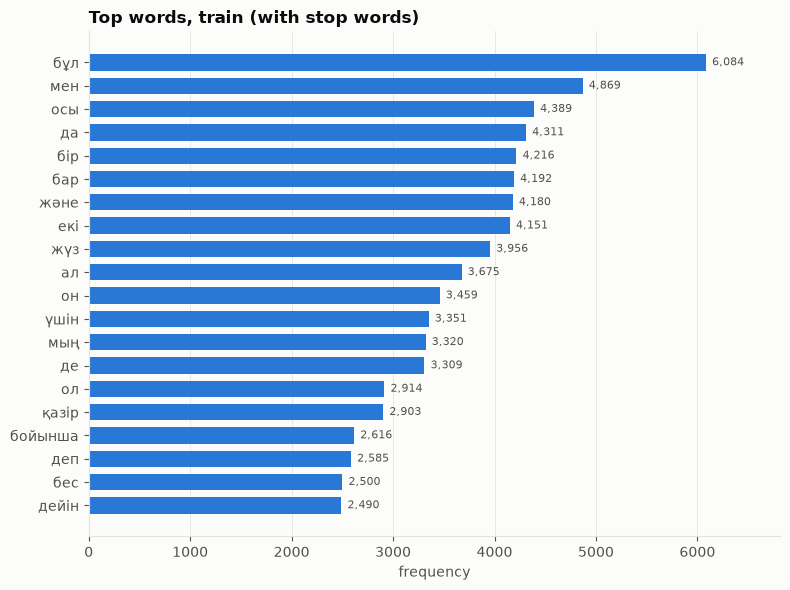

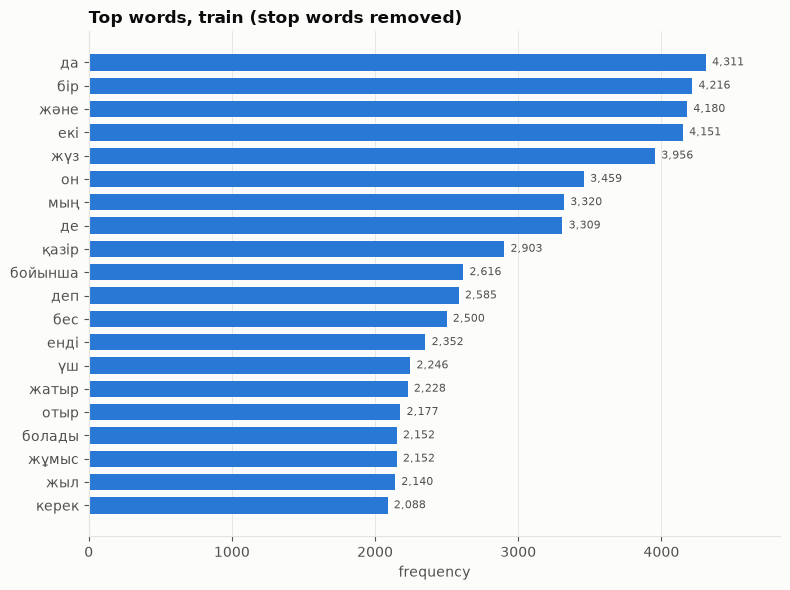

In [15]:
barh(*zip(*freq_raw.most_common(20)), "Top words, train (with stop words)",
     FIGURES_DIR / "top_words_raw.png", "frequency")
barh(*zip(*freq_clean.most_common(20)), "Top words, train (stop words removed)",
     FIGURES_DIR / "top_words_clean.png", "frequency")

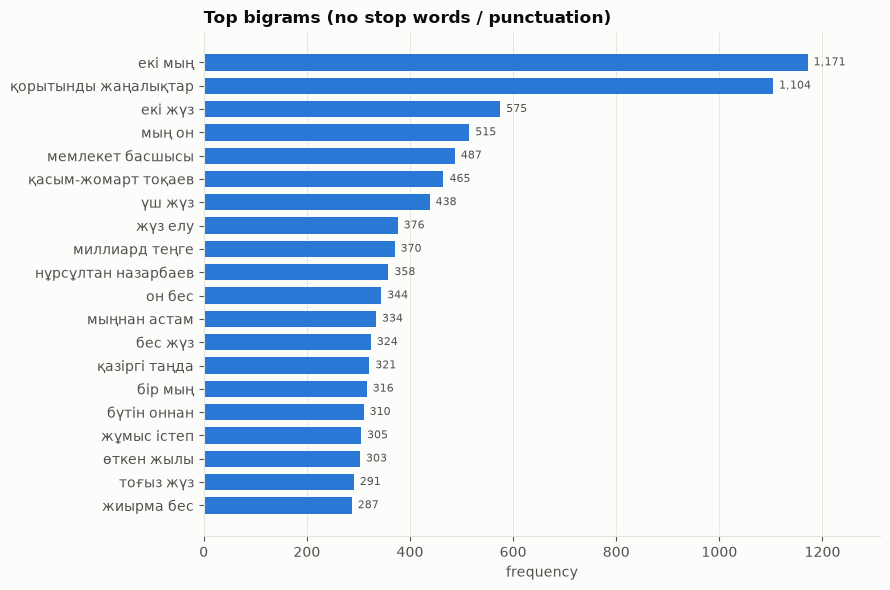

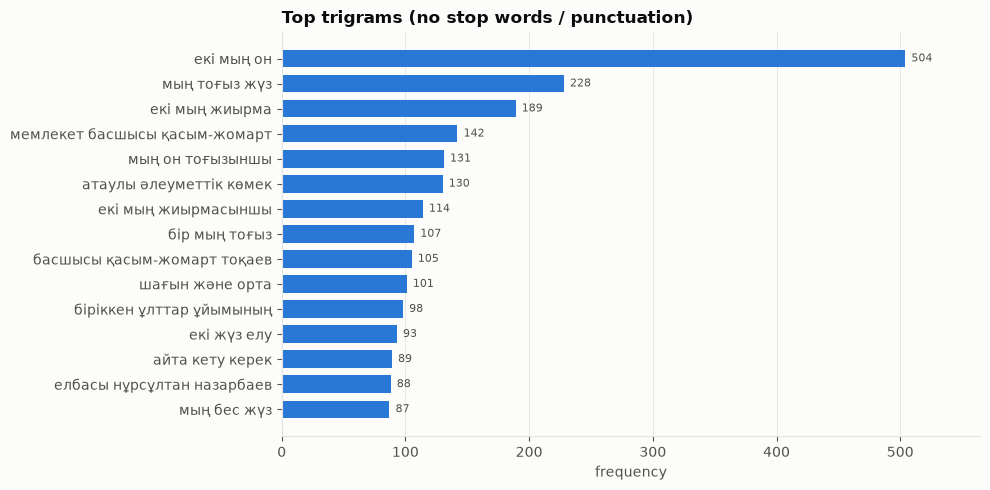

In [16]:
barh(*zip(*freq_bigrams.most_common(20)), "Top bigrams (no stop words / punctuation)",
     FIGURES_DIR / "top_bigrams.png", "frequency", figsize=(9, 6))
barh(*zip(*freq_trigrams.most_common(15)), "Top trigrams (no stop words / punctuation)",
     FIGURES_DIR / "top_trigrams.png", "frequency", figsize=(10, 5))

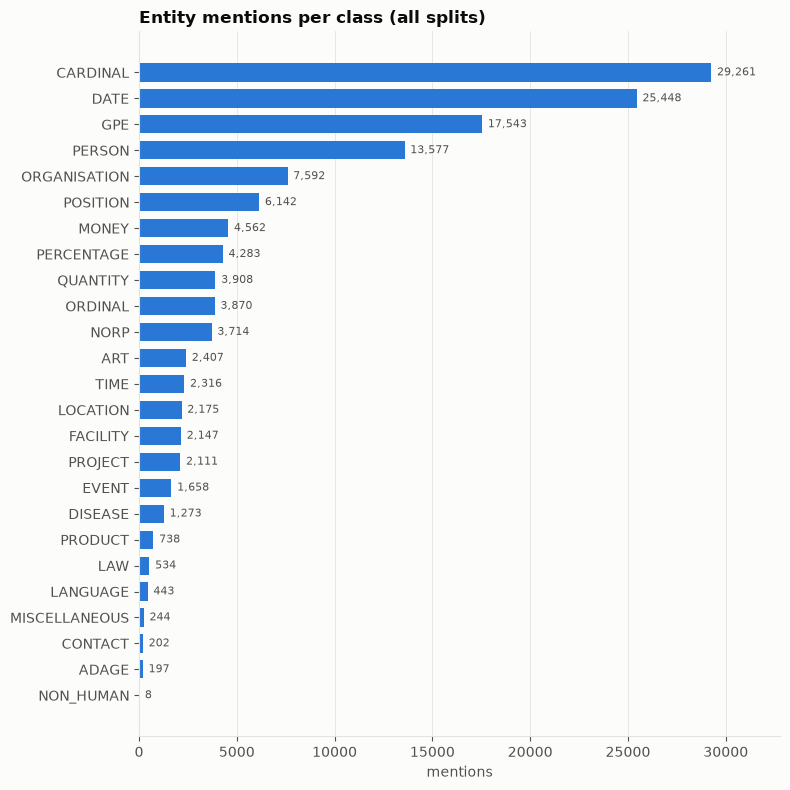

In [17]:
mentions = entity_mentions(all_sents)
type_counts = mentions["type"].value_counts()
type_counts.rename_axis("type").reset_index(name="mentions").to_csv(RESULTS_DIR / "entity_counts.csv", index=False)
barh(type_counts.index, type_counts.values, "Entity mentions per class (all splits)",
     FIGURES_DIR / "entity_distribution.png", "mentions", figsize=(8, 8))

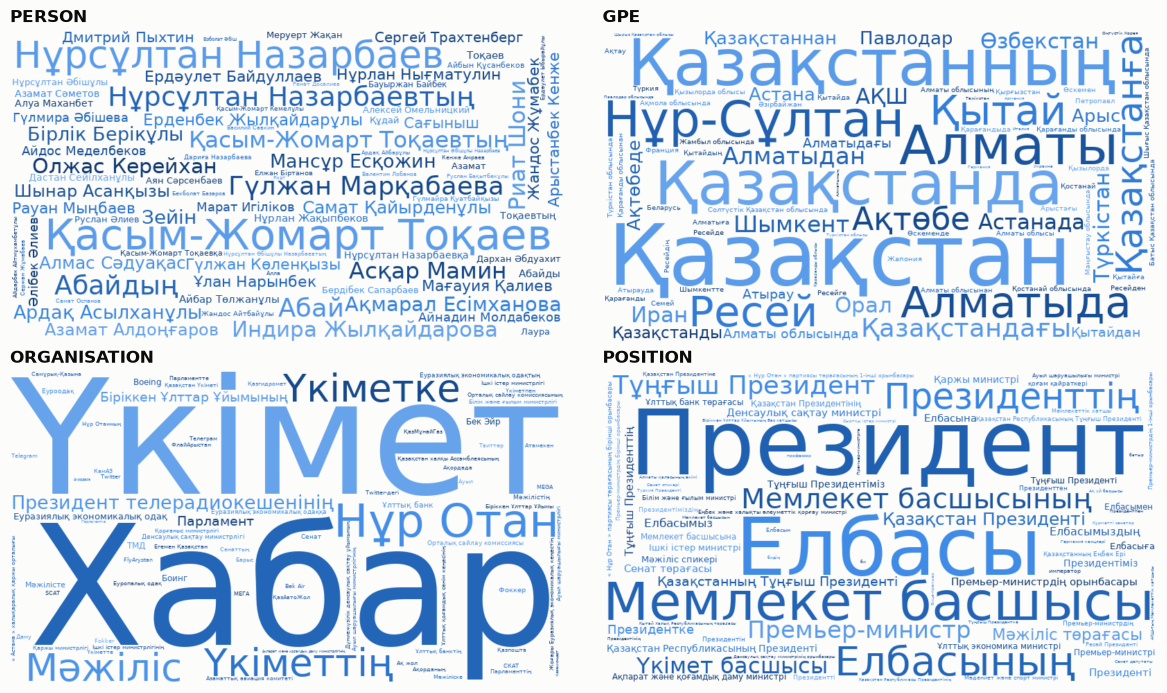

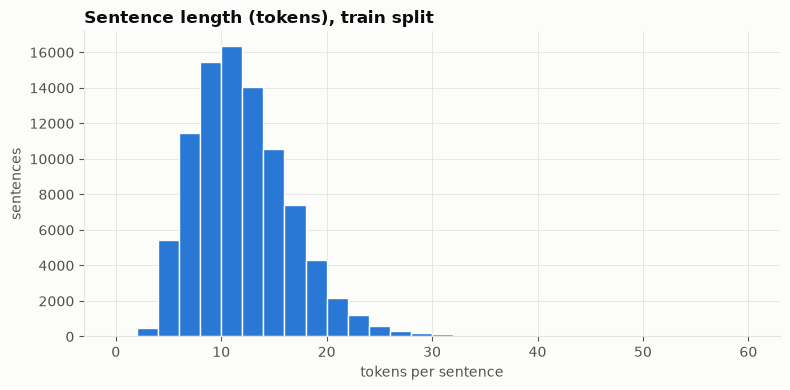

In [18]:
make_wordclouds(mentions, FIGURES_DIR / "wordcloud_entities.png")
plot_sentence_lengths(train_sents, FIGURES_DIR / "sentence_lengths.png")

### Stemming vs lemmatization
Accuracy against held-out UD Kazakh-KTB gold lemmas (overall and on words not seen in UD train),
vocabulary reduction on KazNERD, and speed.

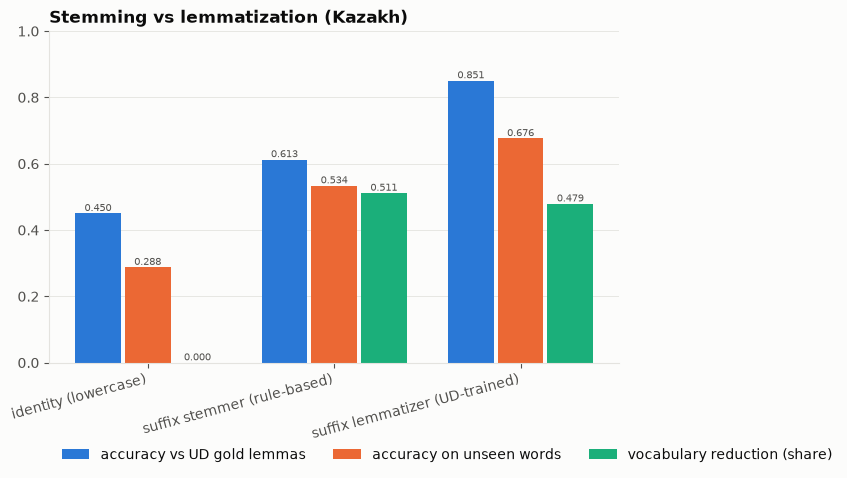

Train: 843,177 word tokens, 64,061 types; stop words = 9.7% of word tokens
136,353 gold entities in 25 classes


,method,ud_accuracy,ud_oov_accuracy,kaznerd_vocab,vocab_reduction_pct,ms_per_1k_words
0,identity (lowercase),0.450,0.288,64061,0.000,0.146
1,suffix stemmer (rule-based),0.613,0.534,31295,51.148,4.131
2,suffix lemmatizer (UD-trained),0.851,0.676,33363,47.920,0.937


In [19]:
norm = compare_normalizers([t for _, toks, _ in train_sents for t in toks])
norm.to_csv(RESULTS_DIR / "stemming_vs_lemmatization.csv", index=False)

total_tokens = sum(freq_raw.values())
eda_summary = {
    "sentences": {s: len(sentences[s]) for s in SPLITS},
    "tokens": {s: sum(len(t) for _, t, _ in sentences[s]) for s in SPLITS},
    "train_word_types": len(freq_raw),
    "train_word_tokens": total_tokens,
    "stopword_token_share": (total_tokens - sum(freq_clean.values())) / total_tokens,
    "entity_mentions": int(len(mentions)),
    "entity_classes": int(mentions["type"].nunique()),
    "mean_entity_length": float(mentions["length"].mean()),
    "ud_test_tokens": norm.attrs["ud_test_tokens"],
    "ud_test_oov": norm.attrs["ud_test_oov"],
}
save_json(eda_summary, RESULTS_DIR / "eda_summary.json")

grouped_bars(list(norm["method"]),
             {"accuracy vs UD gold lemmas": list(norm["ud_accuracy"]),
              "accuracy on unseen words": list(norm["ud_oov_accuracy"]),
              "vocabulary reduction (share)": list(norm["vocab_reduction_pct"] / 100)},
             "Stemming vs lemmatization (Kazakh)", FIGURES_DIR / "stem_vs_lemma.png", ylim=(0, 1))
print(f"Train: {eda_summary['train_word_tokens']:,} word tokens, {eda_summary['train_word_types']:,} types; "
      f"stop words = {eda_summary['stopword_token_share']:.1%} of word tokens")
print(f"{eda_summary['entity_mentions']:,} gold entities in {eda_summary['entity_classes']} classes")
norm.round(3)

## 4. SQLite database

Tables: `entity_types`, `sentences`, `tokens` (with lowercase form, stem, lemma, stop-word flag), `entities`,
`keywords`, and the model tables `models`, `model_scores`, `class_scores`, `predicted_entities`, `errors`,
`user_queries`, `user_query_entities`. The ER diagram is in `docs/er_diagram.png`.

In [20]:
SCHEMA_SQL = """
PRAGMA foreign_keys = ON;

-- Reference table: the 25 KazNERD entity classes
CREATE TABLE IF NOT EXISTS entity_types (
    type_code   TEXT PRIMARY KEY,
    description TEXT NOT NULL
);

-- Corpus: one row per sentence
CREATE TABLE IF NOT EXISTS sentences (
    sentence_id INTEGER PRIMARY KEY,
    split       TEXT    NOT NULL CHECK (split IN ('train', 'valid', 'test')),
    n_tokens    INTEGER NOT NULL,
    text        TEXT    NOT NULL
);

-- Corpus: one row per token, with preprocessing results
CREATE TABLE IF NOT EXISTS tokens (
    sentence_id INTEGER NOT NULL REFERENCES sentences (sentence_id),
    position    INTEGER NOT NULL,
    token       TEXT    NOT NULL,
    lower       TEXT    NOT NULL,
    stem        TEXT    NOT NULL,
    lemma       TEXT    NOT NULL,
    is_stopword INTEGER NOT NULL CHECK (is_stopword IN (0, 1)),
    tag         TEXT    NOT NULL,          -- gold IOB2 tag
    PRIMARY KEY (sentence_id, position)
) WITHOUT ROWID;

-- Gold entity spans (end_pos is exclusive)
CREATE TABLE IF NOT EXISTS entities (
    entity_id   INTEGER PRIMARY KEY,
    sentence_id INTEGER NOT NULL REFERENCES sentences (sentence_id),
    type_code   TEXT    NOT NULL REFERENCES entity_types (type_code),
    start_pos   INTEGER NOT NULL,
    end_pos     INTEGER NOT NULL,
    n_tokens    INTEGER NOT NULL,
    text        TEXT    NOT NULL
);

-- Context keywords per entity type (TF-IDF over words around mentions)
CREATE TABLE IF NOT EXISTS keywords (
    type_code TEXT    NOT NULL REFERENCES entity_types (type_code),
    rank      INTEGER NOT NULL,
    term      TEXT    NOT NULL,
    score     REAL    NOT NULL,
    PRIMARY KEY (type_code, rank)
);

-- Trained models and their resource usage
CREATE TABLE IF NOT EXISTS models (
    model_id        INTEGER PRIMARY KEY,
    name            TEXT UNIQUE NOT NULL,
    description     TEXT,
    train_sentences INTEGER,
    n_features      INTEGER,
    train_time_s    REAL,
    predict_time_s  REAL,
    peak_mem_mb     REAL,
    created_at      TEXT NOT NULL
);

-- Overall test-set scores (one row per model)
CREATE TABLE IF NOT EXISTS model_scores (
    model_id        INTEGER PRIMARY KEY REFERENCES models (model_id),
    accuracy        REAL,
    precision_micro REAL,
    recall_micro    REAL,
    f1_micro        REAL,
    f1_macro        REAL
);

-- Per-class test-set scores
CREATE TABLE IF NOT EXISTS class_scores (
    model_id  INTEGER NOT NULL REFERENCES models (model_id),
    type_code TEXT    NOT NULL REFERENCES entity_types (type_code),
    precision REAL, recall REAL, f1 REAL, support INTEGER,
    PRIMARY KEY (model_id, type_code)
);

-- Entities predicted on the test split
CREATE TABLE IF NOT EXISTS predicted_entities (
    pred_id     INTEGER PRIMARY KEY,
    model_id    INTEGER NOT NULL REFERENCES models (model_id),
    sentence_id INTEGER NOT NULL REFERENCES sentences (sentence_id),
    type_code   TEXT    NOT NULL REFERENCES entity_types (type_code),
    start_pos   INTEGER NOT NULL,
    end_pos     INTEGER NOT NULL,
    text        TEXT    NOT NULL
);

-- Span-level errors on the test split
CREATE TABLE IF NOT EXISTS errors (
    error_id    INTEGER PRIMARY KEY,
    model_id    INTEGER NOT NULL REFERENCES models (model_id),
    sentence_id INTEGER NOT NULL REFERENCES sentences (sentence_id),
    error_type  TEXT    NOT NULL CHECK (error_type IN
                ('missed', 'spurious', 'type_error', 'boundary_error', 'type_and_boundary')),
    gold_type   TEXT REFERENCES entity_types (type_code),
    pred_type   TEXT REFERENCES entity_types (type_code),
    gold_text   TEXT,
    pred_text   TEXT,
    context     TEXT
);

-- Texts typed by the user and the entities found
CREATE TABLE IF NOT EXISTS user_queries (
    query_id   INTEGER PRIMARY KEY,
    model_id   INTEGER REFERENCES models (model_id),
    input_text TEXT NOT NULL,
    created_at TEXT NOT NULL
);

CREATE TABLE IF NOT EXISTS user_query_entities (
    id        INTEGER PRIMARY KEY,
    query_id  INTEGER NOT NULL REFERENCES user_queries (query_id),
    type_code TEXT    NOT NULL REFERENCES entity_types (type_code),
    text      TEXT    NOT NULL
);

CREATE INDEX IF NOT EXISTS idx_tokens_lower      ON tokens (lower);
CREATE INDEX IF NOT EXISTS idx_entities_type     ON entities (type_code, text);
CREATE INDEX IF NOT EXISTS idx_entities_sentence ON entities (sentence_id);
CREATE INDEX IF NOT EXISTS idx_pred_lookup       ON predicted_entities (model_id, sentence_id, start_pos, end_pos);
CREATE INDEX IF NOT EXISTS idx_errors_model      ON errors (model_id, error_type);
"""

MODEL_TABLES = ("model_scores", "class_scores", "predicted_entities", "errors")


def connect(path=DB_PATH):
    conn = sqlite3.connect(path)
    conn.execute("PRAGMA foreign_keys = ON")
    return conn


def create_schema(conn, reset=False):
    if reset:
        tables = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")]
        conn.execute("PRAGMA foreign_keys = OFF")
        for t in tables:
            conn.execute(f"DROP TABLE IF EXISTS {t}")
        conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(SCHEMA_SQL)


def load_corpus(conn, df, sentences_by_split, keywords_df=None, chunksize=CSV_CHUNKSIZE):
    """Fill entity_types, sentences, tokens (with stems/lemmas/stop flags), entities, keywords."""
    conn.executemany("INSERT OR REPLACE INTO entity_types VALUES (?, ?)", ENTITY_TYPES.items())

    sent_rows, ent_rows = [], []
    for split in SPLITS:
        for sid, tokens, tags in sentences_by_split[split]:
            sent_rows.append((sid, split, len(tokens), " ".join(tokens)))
            for etype, s, e in get_spans(tags):
                ent_rows.append((sid, etype, s, e, e - s, span_text(tokens, s, e)))
    conn.executemany("INSERT INTO sentences VALUES (?, ?, ?, ?)", sent_rows)
    conn.executemany("INSERT INTO entities (sentence_id, type_code, start_pos, end_pos, n_tokens, text) "
                     "VALUES (?, ?, ?, ?, ?, ?)", ent_rows)

    # normalise each distinct form once, then map (1.3M tokens -> ~150k forms)
    stopwords = load_stopwords()
    lemmatizer = get_lemmatizer()
    tok = df[["sentence_id", "position", "token", "tag"]].copy()
    tok["token"] = tok["token"].astype(str)
    tok["lower"] = tok["token"].str.lower()
    uniq = pd.Series(tok["lower"].unique())
    stem_map = dict(zip(uniq, uniq.map(stem)))
    lemma_map = dict(zip(uniq, uniq.map(lemmatizer.lemmatize)))
    tok["stem"] = tok["lower"].map(stem_map)
    tok["lemma"] = tok["lower"].map(lemma_map)
    tok["is_stopword"] = tok["lower"].isin(stopwords).astype("int8")
    tok["tag"] = tok["tag"].astype(str)
    cols = ["sentence_id", "position", "token", "lower", "stem", "lemma", "is_stopword", "tag"]
    tok[cols].to_sql("tokens", conn, if_exists="append", index=False, chunksize=chunksize)

    if keywords_df is not None and len(keywords_df):
        keywords_df[["type_code", "rank", "term", "score"]].to_sql("keywords", conn, if_exists="append", index=False)
    conn.commit()
    return {"sentences": len(sent_rows), "entities": len(ent_rows), "tokens": len(tok)}


def table_counts(conn):
    tables = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")]
    return {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables}


def store_model_results(conn, name, description, info, metrics, pred_rows, errors_df):
    """Replace all stored results of model `name` with the new run."""
    row = conn.execute("SELECT model_id FROM models WHERE name = ?", (name,)).fetchone()
    if row:
        for t in MODEL_TABLES:
            conn.execute(f"DELETE FROM {t} WHERE model_id = ?", (row[0],))
        conn.execute("DELETE FROM user_query_entities WHERE query_id IN "
                     "(SELECT query_id FROM user_queries WHERE model_id = ?)", (row[0],))
        conn.execute("DELETE FROM user_queries WHERE model_id = ?", (row[0],))
        conn.execute("DELETE FROM models WHERE model_id = ?", (row[0],))
    cur = conn.execute(
        "INSERT INTO models (name, description, train_sentences, n_features, train_time_s, "
        "predict_time_s, peak_mem_mb, created_at) VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
        (name, description, info.get("train_sentences"), info.get("n_features"),
         info.get("train_time_s"), info.get("predict_time_s"), info.get("peak_mem_mb"),
         datetime.now().isoformat(timespec="seconds")))
    mid = cur.lastrowid
    conn.execute("INSERT INTO model_scores VALUES (?, ?, ?, ?, ?, ?)",
                 (mid, metrics["accuracy"], metrics["precision_micro"], metrics["recall_micro"],
                  metrics["f1_micro"], metrics["f1_macro"]))
    conn.executemany("INSERT INTO class_scores VALUES (?, ?, ?, ?, ?, ?)",
                     [(mid, r.entity_type, r.precision, r.recall, r.f1, int(r.support))
                      for r in metrics["per_class"].itertuples()])
    conn.executemany("INSERT INTO predicted_entities (model_id, sentence_id, type_code, start_pos, "
                     "end_pos, text) VALUES (?, ?, ?, ?, ?, ?)", [(mid, *r) for r in pred_rows])
    if len(errors_df):
        e = errors_df.astype(object).where(errors_df.notna(), None)
        conn.executemany("INSERT INTO errors (model_id, sentence_id, error_type, gold_type, pred_type, "
                         "gold_text, pred_text, context) VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
                         [(mid, *r) for r in e.itertuples(index=False)])
    conn.commit()
    return mid


def log_user_query(conn, model_name, text, entities):
    row = conn.execute("SELECT model_id FROM models WHERE name = ?", (model_name,)).fetchone()
    cur = conn.execute("INSERT INTO user_queries (model_id, input_text, created_at) VALUES (?, ?, ?)",
                       (row[0] if row else None, text, datetime.now().isoformat(timespec="seconds")))
    conn.executemany("INSERT INTO user_query_entities (query_id, type_code, text) VALUES (?, ?, ?)",
                     [(cur.lastrowid, e["type"], e["text"]) for e in entities])
    conn.commit()

In [21]:
print_header("4. Build SQLite database")
keywords = context_keywords(train_sents, stop)
conn = connect()
try:
    with ResourceMonitor() as mon:
        create_schema(conn, reset=True)
        load_corpus(conn, tokens_df, sentences, keywords)
    counts = table_counts(conn)
finally:
    conn.close()
print(f"Database {DB_PATH.name}: {DB_PATH.stat().st_size / 2**20:.1f} MB, built in {mon.seconds:.1f} s")
print("Model tables are filled in section 5 (training).")
pd.Series(counts, name="rows").to_frame()


4. Build SQLite database


Database kaznerd.db: 140.3 MB, built in 11.7 s
Model tables are filled in section 5 (training).


,rows
class_scores,0
entities,136353
entity_types,25
errors,0
keywords,375
model_scores,0
models,0
predicted_entities,0
sentences,112702
tokens,1302352


## 5. Models: features, taggers, evaluation

All models share one interface, `fit(sentences)` / `predict(token_lists)` / `save`:
* **LookupBaseline** — the most frequent tag of each word form seen in training (otherwise `O`)
* **WindowSGDTagger** — a per-token linear classifier on a BoW / TF-IDF / Word2Vec window
* **CRFTagger** — a linear-chain CRF (python-crfsuite) with hand-crafted features

The transformer is in section 11 (it needs a GPU).

### 5.1 Features: CRF features and window representations (BoW, TF-IDF, Word2Vec)

In [22]:
CONTEXT = (-2, -1, 1, 2)


@lru_cache(maxsize=500_000)
def cached_stem(token):
    return stem(token)


def word_shape(token):
    """'Астана' -> 'Xx', '2024' -> 'd', '55-ші' -> 'd-x' (repeated classes collapsed)."""
    shape = re.sub(r"[^\W\d_]", lambda m: "X" if m.group().isupper() else "x", token)
    shape = re.sub(r"\d", "d", shape)
    return re.sub(r"(.)\1+", r"\1", shape)


def crf_token_features(tokens, i):
    w = tokens[i]
    lw = w.lower()
    f = {
        "bias": 1.0, "w": lw, "stem": cached_stem(w), "suf2": lw[-2:], "suf3": lw[-3:],
        "suf4": lw[-4:], "pre3": lw[:3], "shape": word_shape(w),
        "title": w.istitle(), "upper": w.isupper(), "digit": w.isdigit(),
        "hasdigit": any(c.isdigit() for c in w), "hyphen": "-" in w,
    }
    for off in CONTEXT:
        j = i + off
        if 0 <= j < len(tokens):
            o = tokens[j]
            f[f"{off}:w"] = o.lower()
            f[f"{off}:stem"] = cached_stem(o)
            f[f"{off}:suf3"] = o.lower()[-3:]
            f[f"{off}:title"] = o.istitle()
            f[f"{off}:shape"] = word_shape(o)
        else:
            f[f"{off}:pad"] = "BOS" if j < 0 else "EOS"
    # bigram feature around the token
    if i > 0:
        f["-1:w|w"] = tokens[i - 1].lower() + "|" + lw
    if i < len(tokens) - 1:
        f["w|+1:w"] = lw + "|" + tokens[i + 1].lower()
    return f


def crf_sentence_features(tokens):
    return [crf_token_features(tokens, i) for i in range(len(tokens))]


def _ortho(tokens, i):
    """Orthographic block shared by all three representations (keeps the comparison fair)."""
    w = tokens[i]
    return {"title": w.istitle(), "upper": w.isupper(), "digit": w.isdigit(),
            "hasdigit": any(c.isdigit() for c in w), "punct": not any(c.isalnum() for c in w),
            "bos": i == 0, "eos": i == len(tokens) - 1, "prev_title": i > 0 and tokens[i - 1].istitle()}


def _context_words(low, i):
    return [low[i + o] for o in CONTEXT if 0 <= i + o < len(low)]


class WindowVectorizer:
    """Turns sentences into one feature row per token.

    kind = 'bow'      — one-hot current word + bag of context words (counts)
           'tfidf'    — char 2-4-gram TF-IDF of the current word + word TF-IDF of context
           'word2vec' — concatenated Word2Vec vectors of positions -2..+2 (trained on train)
    """

    def __init__(self, kind):
        assert kind in ("bow", "tfidf", "word2vec")
        self.kind = kind
        self.ortho = DictVectorizer()

    @staticmethod
    def _flatten(sents):
        rows_ortho, cur, ctx, windows = [], [], [], []
        for tokens in sents:
            low = [t.lower() for t in tokens]
            for i in range(len(tokens)):
                rows_ortho.append(_ortho(tokens, i))
                cur.append(low[i])
                ctx.append(_context_words(low, i))
                windows.append([low[i + o] if 0 <= i + o < len(low) else None for o in (-2, -1, 0, 1, 2)])
        return rows_ortho, cur, ctx, windows

    def fit_transform(self, sents):
        rows_ortho, cur, ctx, windows = self._flatten(sents)
        o = self.ortho.fit_transform(rows_ortho)
        if self.kind == "bow":
            self.vec = DictVectorizer()
            x = self.vec.fit_transform(self._bow_dicts(cur, ctx))
        elif self.kind == "tfidf":
            self.char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                                            sublinear_tf=True, max_features=200_000)
            self.ctx_vec = TfidfVectorizer(token_pattern=r"\S+", min_df=2, sublinear_tf=True, lowercase=False)
            x = sparse.hstack([self.char_vec.fit_transform(cur),
                               self.ctx_vec.fit_transform([" ".join(c) for c in ctx])])
        else:
            from gensim.models import Word2Vec
            corpus = [[t.lower() for t in s] for s in sents]
            self.w2v = Word2Vec(corpus, vector_size=W2V_DIM, window=W2V_WINDOW, min_count=2, sg=1,
                                epochs=W2V_EPOCHS, workers=2, seed=SEED)
            return np.hstack([self._w2v_matrix(windows), o.toarray().astype(np.float32)])
        return sparse.hstack([x, o]).tocsr()

    def transform(self, sents):
        rows_ortho, cur, ctx, windows = self._flatten(sents)
        o = self.ortho.transform(rows_ortho)
        if self.kind == "bow":
            x = self.vec.transform(self._bow_dicts(cur, ctx))
        elif self.kind == "tfidf":
            x = sparse.hstack([self.char_vec.transform(cur),
                               self.ctx_vec.transform([" ".join(c) for c in ctx])])
        else:
            return np.hstack([self._w2v_matrix(windows), o.toarray().astype(np.float32)])
        return sparse.hstack([x, o]).tocsr()

    @staticmethod
    def _bow_dicts(cur, ctx):
        dicts = []
        for w, c in zip(cur, ctx):
            d = {"w0=" + w: 1}
            for cw in c:
                d["ctx=" + cw] = d.get("ctx=" + cw, 0) + 1
            dicts.append(d)
        return dicts

    def _w2v_matrix(self, windows):
        kv = self.w2v.wv
        dim = kv.vector_size
        x = np.zeros((len(windows), dim * 5 + 1), dtype=np.float32)
        for r, win in enumerate(windows):
            for k, w in enumerate(win):
                if w is not None and w in kv.key_to_index:
                    v = kv[w]
                    x[r, k * dim:(k + 1) * dim] = v / (np.linalg.norm(v) + 1e-8)
            x[r, -1] = float(win[2] not in kv.key_to_index)   # OOV flag for the current word
        return x  # dense: a CSR copy of a dense block would triple memory

    @property
    def n_features(self):
        if self.kind == "bow":
            return len(self.vec.vocabulary_)
        if self.kind == "tfidf":
            return len(self.char_vec.vocabulary_) + len(self.ctx_vec.vocabulary_)
        return self.w2v.wv.vector_size * 5 + 1


pd.Series(crf_token_features(demo_tokens, 1)).to_frame("features of 'Тоқаев'").T

,bias,w,stem,suf2,suf3,suf4,pre3,shape,title,upper,...,1:suf3,1:title,1:shape,2:w,2:stem,2:suf3,2:title,2:shape,-1:w|w,w|+1:w
features of 'Тоқаев',1.0,тоқаев,тоқаев,ев,аев,қаев,тоқ,Xx,True,False,...,024,False,d,жылғы,жылғ,лғы,False,x,қасым-жомарт|тоқаев,тоқаев|2024


### 5.2 Taggers

In [23]:
class LookupBaseline:
    name = "baseline_lookup"
    description = "Most frequent tag per word form (exact, then lowercase), else O"

    def fit(self, sents):
        exact, lower = defaultdict(Counter), defaultdict(Counter)
        for tokens, tags in sents:
            for t, g in zip(tokens, tags):
                exact[t][g] += 1
                lower[t.lower()][g] += 1
        self.exact = {t: c.most_common(1)[0][0] for t, c in exact.items()}
        self.lower = {t: c.most_common(1)[0][0] for t, c in lower.items()}
        return self

    def predict(self, token_lists):
        return [[self.exact.get(t) or self.lower.get(t.lower(), "O") for t in tokens] for tokens in token_lists]

    def save(self, path):
        joblib.dump(self, path, compress=3)


class WindowSGDTagger:
    """Independent per-token classification; same classifier for every representation."""

    def __init__(self, kind, max_sentences=LINEAR_TRAIN_SENTENCES):
        self.kind = kind
        self.name = f"sgd_{kind}"
        self.description = {"bow": "SGD logistic regression on Bag-of-Words window",
                            "tfidf": "SGD logistic regression on char/word TF-IDF window",
                            "word2vec": "SGD logistic regression on Word2Vec window"}[kind]
        self.max_sentences = max_sentences

    def fit(self, sents):
        sents = list(sents)
        if self.max_sentences and len(sents) > self.max_sentences:
            sents = random.Random(SEED).sample(sents, self.max_sentences)
        self.train_sentences = len(sents)
        self.vectorizer = WindowVectorizer(self.kind)
        x = self.vectorizer.fit_transform([t for t, _ in sents])
        y = np.array([g for _, tags in sents for g in tags])
        self.clf = SGDClassifier(loss="log_loss", alpha=1e-6 if self.kind == "word2vec" else 1e-5,
                                 max_iter=30, tol=1e-4, n_jobs=-1, random_state=SEED)
        self.clf.fit(x, y)
        return self

    def predict(self, token_lists, batch=5000):
        out = []
        for b in range(0, len(token_lists), batch):
            chunk = token_lists[b:b + batch]
            flat = self.clf.predict(self.vectorizer.transform(chunk))
            pos = 0
            for tokens in chunk:
                out.append(list(flat[pos:pos + len(tokens)]))
                pos += len(tokens)
        return out

    def save(self, path):
        joblib.dump(self, path, compress=3)


class CRFTagger:
    name = "crf"
    description = "Linear-chain CRF (L-BFGS, L1+L2) with lexical, suffix, stem and shape features"

    def __init__(self, model_file="crf.crfsuite", c1=CRF_C1, c2=CRF_C2, max_iterations=CRF_MAX_ITERATIONS):
        self.model_file = model_file      # stored relative to MODELS_DIR so the project is movable
        self.params = {"c1": c1, "c2": c2, "max_iterations": max_iterations,
                       "feature.possible_transitions": True}
        self._tagger = None

    @property
    def model_path(self):
        return str(MODELS_DIR / self.model_file)

    def fit(self, sents):
        trainer = pycrfsuite.Trainer(verbose=False)
        trainer.set_params(self.params)
        for tokens, tags in sents:      # features are generated sentence by sentence
            trainer.append(crf_sentence_features(tokens), tags)
        Path(self.model_path).parent.mkdir(parents=True, exist_ok=True)
        trainer.train(self.model_path)
        self.train_log = getattr(trainer.logparser, "last_iteration", None)
        self._tagger = None
        return self

    @property
    def tagger(self):
        if self._tagger is None:
            if not Path(self.model_path).exists():
                raise FileNotFoundError(f"{self.model_path} not found — train the CRF first.")
            self._tagger = pycrfsuite.Tagger()
            self._tagger.open(self.model_path)
        return self._tagger

    def predict(self, token_lists):
        return [self.tagger.tag(crf_sentence_features(tokens)) if tokens else [] for tokens in token_lists]

    def top_features(self, k=20):
        info = self.tagger.info()
        state = sorted(info.state_features.items(), key=lambda kv: -kv[1])
        trans = sorted(info.transitions.items(), key=lambda kv: -kv[1])
        return state[:k], trans[:k]

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_tagger"] = None          # the C tagger is not picklable; reopened lazily
        return state

    def save(self, path):
        joblib.dump(self, path)


def build_models():
    """All locally trainable models, baseline first."""
    return [LookupBaseline(), WindowSGDTagger("bow"), WindowSGDTagger("tfidf"),
            WindowSGDTagger("word2vec"), CRFTagger()]


def model_path(name):
    return MODELS_DIR / f"{name}.joblib"


def load_model(name):
    path = model_path(name)
    if not path.exists():
        raise FileNotFoundError(f"Model '{name}' not found at {path} — train models first (section 5).")
    return joblib.load(path)

### 5.3 Evaluation: seqeval metrics, confusion matrix, span-level error analysis

In [24]:
def evaluate(y_true, y_pred):
    """Entity-level (seqeval, conlleval-style) micro/macro scores plus token accuracy."""
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    per_class = (pd.DataFrame(report).T.drop(index=["micro avg", "macro avg", "weighted avg"], errors="ignore")
                 .rename(columns={"f1-score": "f1"}).reset_index(names="entity_type"))
    per_class["support"] = per_class["support"].astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_micro": precision_score(y_true, y_pred, zero_division=0),
        "recall_micro": recall_score(y_true, y_pred, zero_division=0),
        "f1_micro": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "per_class": per_class.sort_values("support", ascending=False),
    }


def _strip(tag):
    return tag[2:] if tag != "O" else "O"


def type_confusion(y_true, y_pred):
    """Token-level confusion matrix over entity types (B-/I- merged), rows = gold."""
    pairs = Counter((_strip(g), _strip(p)) for gs, ps in zip(y_true, y_pred) for g, p in zip(gs, ps))
    gold_freq = Counter()
    for (g, _), n in pairs.items():
        gold_freq[g] += n
    labels = ["O"] + [l for l, _ in gold_freq.most_common() if l != "O"]
    mat = pd.DataFrame(0, index=labels, columns=labels, dtype=np.int64)
    for (g, p), n in pairs.items():
        if g in mat.index and p in mat.columns:
            mat.loc[g, p] += n
    return mat


def plot_confusion(mat, title, path, drop_o_diagonal=True, show=True):
    """Row-normalised heatmap; the dominant O->O cell is hidden so entity errors stay visible."""
    norm_mat = mat.div(mat.sum(axis=1).replace(0, 1), axis=0)
    data = norm_mat.to_numpy().copy()
    if drop_o_diagonal:
        data[0, 0] = np.nan
    setup_style()
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(data, cmap=SEQ_CMAP, vmin=0, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(len(mat.columns)))
    ax.set_xticklabels(mat.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(mat.index)))
    ax.set_yticklabels(mat.index, fontsize=8)
    ax.set_xlabel("predicted type")
    ax.set_ylabel("gold type")
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            if not np.isnan(v) and v >= 0.01:
                ax.text(j, i, f"{v:.2f}".lstrip("0"), ha="center", va="center", fontsize=6,
                        color="white" if v > 0.55 else INK)
    fig.colorbar(im, ax=ax, fraction=0.03, label="share of gold tokens")
    fig.tight_layout()
    save_and_show(fig, path, show=show)


def error_analysis(sents, predictions):
    """Classify every span-level error.

    error_type: type_error (same span, other type), boundary_error (overlap, same type),
                type_and_boundary, missed (no overlapping prediction), spurious (no overlapping gold).
    """
    rows = []
    for (sid, tokens, gold_tags), pred_tags in zip(sents, predictions):
        gold = get_spans(gold_tags)
        pred = get_spans(pred_tags)
        pred_set = set(pred)
        for g in gold:
            if g in pred_set:
                continue
            overlaps = [p for p in pred if p[1] < g[2] and g[1] < p[2]]
            if not overlaps:
                kind, p = "missed", None
            else:
                p = max(overlaps, key=lambda s: min(s[2], g[2]) - max(s[1], g[1]))
                if (p[1], p[2]) == (g[1], g[2]):
                    kind = "type_error"
                elif p[0] == g[0]:
                    kind = "boundary_error"
                else:
                    kind = "type_and_boundary"
            rows.append(_err_row(sid, tokens, kind, g, p))
        gold_set = set(gold)
        for p in pred:
            if p in gold_set:
                continue
            if not any(g[1] < p[2] and p[1] < g[2] for g in gold):
                rows.append(_err_row(sid, tokens, "spurious", None, p))
    return pd.DataFrame(rows, columns=["sentence_id", "error_type", "gold_type", "pred_type",
                                       "gold_text", "pred_text", "context"])


def _err_row(sid, tokens, kind, g, p):
    lo = min(x[1] for x in (g, p) if x)
    hi = max(x[2] for x in (g, p) if x)
    return {
        "sentence_id": sid, "error_type": kind,
        "gold_type": g[0] if g else None, "pred_type": p[0] if p else None,
        "gold_text": span_text(tokens, g[1], g[2]) if g else None,
        "pred_text": span_text(tokens, p[1], p[2]) if p else None,
        "context": span_text(tokens, max(0, lo - 4), min(len(tokens), hi + 4)),
    }


def predicted_entities(sents, predictions):
    """Rows (sentence_id, type, start, end, text) for storing predictions in SQLite."""
    rows = []
    for (sid, tokens, _), tags in zip(sents, predictions):
        for etype, s, e in get_spans(tags):
            rows.append((sid, etype, s, e, span_text(tokens, s, e)))
    return rows


def plot_comparison(table, show=True):
    order = ["baseline_lookup", "sgd_bow", "sgd_tfidf", "sgd_word2vec", "crf", "transformer"]
    t = table.set_index("model").reindex([m for m in order if m in set(table["model"])])
    grouped_bars(list(t.index), {"F1 micro": list(t["f1_micro"]), "F1 macro": list(t["f1_macro"]),
                                 "precision": list(t["precision_micro"]), "recall": list(t["recall_micro"])},
                 "Test-set scores by model (entity level, seqeval)",
                 FIGURES_DIR / "model_comparison.png", ylim=(0, 1.05), show=show)


def evaluate_and_record(tagger, test_sentences, info):
    """Predict the test split, score it, analyse errors, store everything (CSV + SQLite)."""
    tokens = [t for _, t, _ in test_sentences]
    gold = [g for _, _, g in test_sentences]
    with ResourceMonitor() as mon:
        pred = tagger.predict(tokens)
    info["predict_time_s"] = mon.seconds
    metrics = evaluate(gold, pred)
    errors = error_analysis(test_sentences, pred)
    name = tagger.name

    metrics["per_class"].to_csv(RESULTS_DIR / f"per_class_{name}.csv", index=False)
    errors.to_csv(RESULTS_DIR / f"errors_{name}.csv", index=False)
    conf = type_confusion(gold, pred)
    conf.to_csv(RESULTS_DIR / f"confusion_{name}.csv")
    plot_confusion(conf, f"Token-level class confusion — {name} (row-normalised)",
                   FIGURES_DIR / f"confusion_{name}.png", show=False)

    conn = connect()
    try:
        store_model_results(conn, name, tagger.description, info, metrics,
                            predicted_entities(test_sentences, pred), errors)
    finally:
        conn.close()

    row = {"model": name, "description": tagger.description,
           **{k: metrics[k] for k in ("accuracy", "precision_micro", "recall_micro", "f1_micro", "f1_macro")},
           **{k: info.get(k) for k in ("train_sentences", "n_features", "train_time_s",
                                       "predict_time_s", "peak_mem_mb")}}
    table = pd.read_csv(COMPARISON_CSV) if COMPARISON_CSV.exists() else pd.DataFrame()
    if len(table):
        table = table[table["model"] != name]
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table.to_csv(COMPARISON_CSV, index=False)
    plot_comparison(table, show=False)
    print(f"  {name:<18} F1 micro {metrics['f1_micro']:.4f} | F1 macro {metrics['f1_macro']:.4f} | "
          f"acc {metrics['accuracy']:.4f} | train {info.get('train_time_s', 0):.0f} s | "
          f"predict {mon.seconds:.1f} s | peak +{info.get('peak_mem_mb', 0):.0f} MB | errors {len(errors):,}")
    return metrics, errors

### 5.4 Training and evaluation on the test split
This cell takes about 25 min, most of it CRF training. The models used are set in `TRAIN_MODELS` (section 0).

In [25]:
print_header("5. Train and evaluate models (test split)")
train_pairs = [(t, g) for _, t, g in sentences["train"]]
for model in build_models():
    if model.name not in TRAIN_MODELS:
        continue
    print(f"Training {model.name} ...", flush=True)
    with ResourceMonitor() as mon:
        model.fit(train_pairs)
    info = {"train_sentences": getattr(model, "train_sentences", len(train_pairs)),
            "n_features": getattr(getattr(model, "vectorizer", None), "n_features", None),
            "train_time_s": mon.seconds, "peak_mem_mb": mon.peak_mb}
    if model.name == "crf":
        info["n_features"] = len(model.tagger.info().state_features)
    if model.name == "baseline_lookup":
        info["n_features"] = len(model.exact)
    model.save(model_path(model.name))
    evaluate_and_record(model, sentences["test"], info)
    del model
print(f"\nComparison table: {COMPARISON_CSV}")


5. Train and evaluate models (test split)
Training baseline_lookup ...


  baseline_lookup    F1 micro 0.4925 | F1 macro 0.3995 | acc 0.9112 | train 1 s | predict 0.0 s | peak +3 MB | errors 6,592
Training sgd_bow ...


  sgd_bow            F1 micro 0.6026 | F1 macro 0.3787 | acc 0.9277 | train 18 s | predict 1.8 s | peak +540 MB | errors 5,621
Training sgd_tfidf ...


  sgd_tfidf          F1 micro 0.6128 | F1 macro 0.3715 | acc 0.9301 | train 25 s | predict 2.1 s | peak +533 MB | errors 5,191
Training sgd_word2vec ...


C:\Users\amirk\PycharmProjects\kaznerd-ner\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


  sgd_word2vec       F1 micro 0.6053 | F1 macro 0.3726 | acc 0.9272 | train 72 s | predict 2.2 s | peak +1365 MB | errors 5,783
Training crf ...


  crf                F1 micro 0.9312 | F1 macro 0.8234 | acc 0.9825 | train 629 s | predict 3.8 s | peak +1098 MB | errors 1,162

Comparison table: C:\Users\amirk\PycharmProjects\kaznerd-ner\reports\results\model_comparison.csv


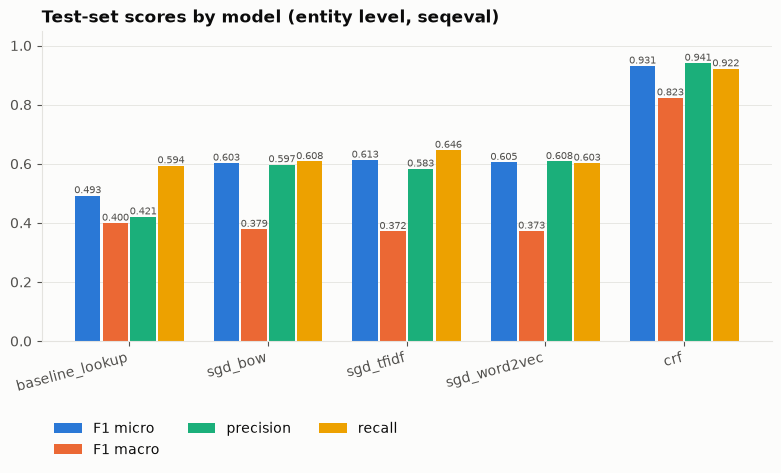

,model,description,accuracy,precision_micro,recall_micro,f1_micro,f1_macro,train_sentences,n_features,train_time_s,predict_time_s,peak_mem_mb
4,crf,"Linear-chain CRF (L-BFGS, L1+L2) with lexical, suffix, stem and shape features",0.9825,0.9408,0.9219,0.9312,0.8234,90228,219104,628.6433,3.8441,1098.0000
2,sgd_tfidf,SGD logistic regression on char/word TF-IDF window,0.9301,0.5828,0.6461,0.6128,0.3715,30000,73507,25.0949,2.1175,532.7070
3,sgd_word2vec,SGD logistic regression on Word2Vec window,0.9272,0.6081,0.6025,0.6053,0.3726,30000,501,71.8228,2.2163,1365.0391
1,sgd_bow,SGD logistic regression on Bag-of-Words window,0.9277,0.5975,0.6079,0.6026,0.3787,30000,79478,18.2284,1.7628,539.9688
0,baseline_lookup,"Most frequent tag per word form (exact, then lowercase), else O",0.9112,0.4207,0.5939,0.4925,0.3995,90228,73008,0.9080,0.0180,2.8984


In [26]:
comparison = pd.read_csv(COMPARISON_CSV).sort_values("f1_micro", ascending=False)
plot_comparison(comparison)
comparison.round(4)

## 6. Analytical SQL queries
The 14 queries use JOIN (including a self-join and a CROSS JOIN), GROUP BY / HAVING, CTEs, scalar and EXISTS
subqueries, and window functions (ROW_NUMBER, RANK, LAG, SUM OVER). Results are loaded into Pandas with
`pd.read_sql_query` and saved to `reports/results/sql_*.csv`.

In [27]:
BEST_MODEL = "(SELECT model_id FROM model_scores ORDER BY f1_micro DESC LIMIT 1)"

QUERIES = {
    "q01_entity_counts": (
        "Mentions, unique surface forms and mean length per class [JOIN, GROUP BY]",
        """
        SELECT e.type_code, t.description,
               COUNT(*)                   AS mentions,
               COUNT(DISTINCT e.text)     AS unique_forms,
               ROUND(AVG(e.n_tokens), 2)  AS avg_tokens
        FROM entities e
        JOIN entity_types t USING (type_code)
        GROUP BY e.type_code, t.description
        ORDER BY mentions DESC;
        """),
    "q02_frequent_classes_by_split": (
        "Classes with at least 500 mentions in a split [JOIN, GROUP BY, HAVING]",
        """
        SELECT s.split, e.type_code, COUNT(*) AS mentions
        FROM entities e
        JOIN sentences s USING (sentence_id)
        GROUP BY s.split, e.type_code
        HAVING COUNT(*) >= 500
        ORDER BY s.split, mentions DESC;
        """),
    "q03_top_entities_per_class": (
        "Top-5 most frequent entities for key classes [CTE, ROW_NUMBER window]",
        """
        WITH counts AS (
            SELECT type_code, text, COUNT(*) AS n
            FROM entities
            GROUP BY type_code, text
        ), ranked AS (
            SELECT *, ROW_NUMBER() OVER (PARTITION BY type_code ORDER BY n DESC, text) AS rn
            FROM counts
        )
        SELECT type_code, rn AS rank, text, n
        FROM ranked
        WHERE rn <= 5 AND type_code IN ('PERSON', 'GPE', 'ORGANISATION', 'LOCATION', 'POSITION')
        ORDER BY type_code, rn;
        """),
    "q04_class_pareto": (
        "Share and cumulative share of mentions per class [CTE, SUM() OVER window]",
        """
        WITH c AS (SELECT type_code, COUNT(*) AS n FROM entities GROUP BY type_code)
        SELECT type_code, n,
               ROUND(100.0 * n / SUM(n) OVER (), 2) AS pct,
               ROUND(100.0 * SUM(n) OVER (ORDER BY n DESC ROWS UNBOUNDED PRECEDING)
                     / SUM(n) OVER (), 2) AS cumulative_pct
        FROM c
        ORDER BY n DESC;
        """),
    "q05_split_statistics": (
        "Sentence length and entity density per split [CTE, LEFT JOIN, aggregation]",
        """
        WITH per_sentence AS (
            SELECT s.sentence_id, s.split, s.n_tokens, COUNT(e.entity_id) AS n_entities
            FROM sentences s
            LEFT JOIN entities e USING (sentence_id)
            GROUP BY s.sentence_id, s.split, s.n_tokens
        )
        SELECT split,
               COUNT(*)                                        AS sentences,
               SUM(n_tokens)                                   AS tokens,
               ROUND(AVG(n_tokens), 2)                         AS avg_tokens,
               ROUND(AVG(n_entities), 3)                       AS avg_entities,
               ROUND(100.0 * SUM(n_entities = 0) / COUNT(*), 1) AS pct_without_entities
        FROM per_sentence
        GROUP BY split
        ORDER BY CASE split WHEN 'train' THEN 1 WHEN 'valid' THEN 2 ELSE 3 END;
        """),
    "q06_entity_dense_sentences": (
        "Sentences with > 3x the average number of entities [nested subquery, HAVING]",
        """
        SELECT s.sentence_id, s.split, s.n_tokens, COUNT(*) AS n_entities, s.text
        FROM sentences s
        JOIN entities e USING (sentence_id)
        GROUP BY s.sentence_id
        HAVING COUNT(*) > (SELECT 3 * AVG(cnt)
                           FROM (SELECT COUNT(*) AS cnt FROM entities GROUP BY sentence_id))
        ORDER BY n_entities DESC
        LIMIT 10;
        """),
    "q07_class_cooccurrence": (
        "Which classes appear together in one sentence [self-JOIN, GROUP BY]",
        """
        SELECT a.type_code AS type_a, b.type_code AS type_b,
               COUNT(DISTINCT a.sentence_id) AS sentences
        FROM entities a
        JOIN entities b ON a.sentence_id = b.sentence_id AND a.type_code < b.type_code
        GROUP BY a.type_code, b.type_code
        ORDER BY sentences DESC
        LIMIT 15;
        """),
    "q08_normalisation_by_class": (
        "Stop-word share and vocabulary of forms / stems / lemmas per class [CASE, COUNT DISTINCT]",
        """
        SELECT CASE WHEN tag = 'O' THEN 'O' ELSE substr(tag, 3) END AS class,
               COUNT(*)                          AS tokens,
               ROUND(100.0 * AVG(is_stopword), 2) AS pct_stopwords,
               COUNT(DISTINCT lower)             AS forms,
               COUNT(DISTINCT stem)              AS stems,
               COUNT(DISTINCT lemma)             AS lemmas
        FROM tokens
        GROUP BY class
        ORDER BY tokens DESC;
        """),
    "q09_model_leaderboard": (
        "Model ranking with gain over the next-weaker model [JOIN, RANK and LAG windows]",
        """
        SELECT m.name, s.f1_micro, s.f1_macro, s.accuracy,
               m.train_time_s, m.peak_mem_mb,
               RANK() OVER (ORDER BY s.f1_micro DESC) AS rank_f1,
               ROUND(s.f1_micro - LAG(s.f1_micro) OVER (ORDER BY s.f1_micro), 4) AS gain_vs_previous
        FROM model_scores s
        JOIN models m USING (model_id)
        ORDER BY s.f1_micro DESC;
        """),
    "q10_hardest_classes_best_model": (
        "Ten weakest classes of the best model [scalar subquery]",
        f"""
        SELECT c.type_code, ROUND(c.precision, 3) AS precision, ROUND(c.recall, 3) AS recall,
               ROUND(c.f1, 3) AS f1, c.support
        FROM class_scores c
        WHERE c.model_id = {BEST_MODEL}
        ORDER BY c.f1
        LIMIT 10;
        """),
    "q11_error_profile": (
        "Error-type distribution per model [JOIN, GROUP BY, SUM() OVER PARTITION]",
        """
        SELECT m.name, e.error_type, COUNT(*) AS n,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY m.name), 1) AS pct
        FROM errors e
        JOIN models m USING (model_id)
        GROUP BY m.name, e.error_type
        ORDER BY m.name, n DESC;
        """),
    "q12_top_confusions_best_model": (
        "Most frequent gold -> predicted class confusions of the best model [subquery, GROUP BY]",
        f"""
        SELECT gold_type, pred_type, COUNT(*) AS n
        FROM errors
        WHERE error_type IN ('type_error', 'type_and_boundary') AND model_id = {BEST_MODEL}
        GROUP BY gold_type, pred_type
        ORDER BY n DESC
        LIMIT 10;
        """),
    "q13_seen_vs_unseen_recall": (
        "Recall on test entities seen vs unseen in train [CTE, EXISTS subquery, LEFT JOIN]",
        """
        WITH train_entities AS (
            SELECT DISTINCT e.type_code, e.text
            FROM entities e JOIN sentences s USING (sentence_id)
            WHERE s.split = 'train'
        ), test_gold AS (
            SELECT e.*,
                   CASE WHEN EXISTS (SELECT 1 FROM train_entities t
                                     WHERE t.type_code = e.type_code AND t.text = e.text)
                        THEN 'seen' ELSE 'unseen' END AS novelty
            FROM entities e JOIN sentences s USING (sentence_id)
            WHERE s.split = 'test'
        )
        SELECT m.name, g.novelty, COUNT(*) AS gold,
               SUM(p.pred_id IS NOT NULL) AS found,
               ROUND(100.0 * SUM(p.pred_id IS NOT NULL) / COUNT(*), 2) AS recall_pct
        FROM test_gold g
        CROSS JOIN models m
        LEFT JOIN predicted_entities p
               ON p.model_id = m.model_id AND p.sentence_id = g.sentence_id
              AND p.start_pos = g.start_pos AND p.end_pos = g.end_pos
              AND p.type_code = g.type_code
        GROUP BY m.name, g.novelty
        ORDER BY m.name, g.novelty;
        """),
    "q14_context_keywords": (
        "Top context keywords signalling each class [subquery, GROUP_CONCAT]",
        """
        SELECT type_code, GROUP_CONCAT(term, ', ') AS keywords
        FROM (SELECT type_code, term FROM keywords WHERE rank <= 8 ORDER BY type_code, rank)
        GROUP BY type_code
        ORDER BY type_code;
        """),
}


def run_query(conn, key):
    title, sql = QUERIES[key]
    return title, pd.read_sql_query(sql, conn)


def run_all_queries(conn, save=True, verbose=True):
    results = {}
    for key in QUERIES:
        try:
            title, df = run_query(conn, key)
        except (sqlite3.Error, pd.errors.DatabaseError) as exc:
            print(f"[{key}] failed: {exc}")
            continue
        results[key] = df
        if save:
            df.to_csv(RESULTS_DIR / f"sql_{key}.csv", index=False)
        if verbose:
            print(f"\n--- {key}: {title} ---")
            print(df.head(15).to_string(index=False, max_colwidth=60) if len(df) else "(no rows)")
    return results

In [28]:
print_header("6. Analytical SQL queries (results also saved as CSV)")
conn = connect()
try:
    sql_results = run_all_queries(conn)
finally:
    conn.close()


6. Analytical SQL queries (results also saved as CSV)



--- q01_entity_counts: Mentions, unique surface forms and mean length per class [JOIN, GROUP BY] ---
   type_code                                        description  mentions  unique_forms  avg_tokens
    CARDINAL         Numerals that are not another numeric type     29261          6018        1.61
        DATE             Absolute or relative dates and periods     25448          7631        2.24
         GPE Geo-political entities: countries, cities, regions     17543          2038        1.20
      PERSON                        People, including fictional     13577          3735        1.83
ORGANISATION                  Companies, agencies, institutions      7592          2298        2.19
    POSITION                           Job titles and positions      6142          1084        2.08
       MONEY                          Monetary values with unit      4562          3229        3.59
  PERCENTAGE                                        Percentages      4283          2488        2.7


--- q05_split_statistics: Sentence length and entity density per split [CTE, LEFT JOIN, aggregation] ---
split  sentences  tokens  avg_tokens  avg_entities  pct_without_entities
train      90228 1043305       11.56         1.212                  32.8
valid      11167  129223       11.57         1.207                  32.6
 test      11307  129824       11.48         1.195                  33.3

--- q06_entity_dense_sentences: Sentences with > 3x the average number of entities [nested subquery, HAVING] ---
 sentence_id split  n_tokens  n_entities                                                         text
       71775 train        31          12 Жиырма үш адам — Қырғызстан , отыз жетісі — Өзбекстан , о...
       71776 train        27          12 23 адам — Қырғызстан , 37-сі — Өзбекстан , 16-сы — Ресей ...
       18211 train        34          10 Он жеті елдің командалары бақ сынаған байрақты додада көк...
       18212 train        33          10 17 елдің командалары бақ сынаған байрақ


--- q07_class_cooccurrence: Which classes appear together in one sentence [self-JOIN, GROUP BY] ---
  type_a       type_b  sentences
CARDINAL         DATE       5529
CARDINAL          GPE       3582
    DATE          GPE       3130
  PERSON     POSITION       2173
    DATE       PERSON       1969
     GPE       PERSON       1926
    DATE ORGANISATION       1700
     ART       PERSON       1574
    DATE     POSITION       1335
CARDINAL       PERSON       1309
CARDINAL ORGANISATION       1169
    DATE        MONEY       1134
    DATE   PERCENTAGE       1108
     GPE ORGANISATION        896
CARDINAL         NORP        835



--- q08_normalisation_by_class: Stop-word share and vocabulary of forms / stems / lemmas per class [CASE, COUNT DISTINCT] ---
       class  tokens  pct_stopwords  forms  stems  lemmas
           O 1036573           9.05  59743  26256   28369
        DATE   56899           9.69   1401    950     963
    CARDINAL   47110           3.41   2426   2239    2230
      PERSON   24849           0.12   4268   3423    3551
         GPE   20979           0.05   1887   1126    1246
ORGANISATION   16640           0.26   2293   1813    1806
       MONEY   16364           1.50    954    913     913
    QUANTITY   12797           2.58    755    661     659
    POSITION   12772           0.14   1198    937     946
  PERCENTAGE   11641           1.50    274    247     240
     PROJECT    5737           0.38    645    529     517
       EVENT    5589           0.77   1010    821     798
    FACILITY    5421           0.46   1309   1084    1071
        TIME    5357           8.44    408    307     309
   


--- q13_seen_vs_unseen_recall: Recall on test entities seen vs unseen in train [CTE, EXISTS subquery, LEFT JOIN] ---
           name novelty  gold  found  recall_pct
baseline_lookup    seen 10206   7690       75.35
baseline_lookup  unseen  3302    332       10.05
            crf    seen 10206   9863       96.64
            crf  unseen  3302   2590       78.44
        sgd_bow    seen 10206   7209       70.63
        sgd_bow  unseen  3302   1003       30.38
      sgd_tfidf    seen 10206   7686       75.31
      sgd_tfidf  unseen  3302   1042       31.56
   sgd_word2vec    seen 10206   7081       69.38
   sgd_word2vec  unseen  3302   1058       32.04

--- q14_context_keywords: Top context keywords signalling each class [subquery, GROUP_CONCAT] ---
    type_code                                                     keywords
        ADAGE қазақта, дегендей, нақыл, халқымыз, демекші, жүйедегі, де...
          ART телерадиокешенінің, пыхтин, омельницкий, әлиев, молдабеко...
     CARDINAL адамн

In [29]:
# any single result is a DataFrame, e.g. the model leaderboard:
sql_results.get("q09_model_leaderboard")

,name,f1_micro,f1_macro,accuracy,train_time_s,peak_mem_mb,rank_f1,gain_vs_previous
0,crf,0.931239,0.823391,0.982461,628.643336,1098.000000,1,0.3184
1,sgd_tfidf,0.612814,0.371527,0.930075,25.094909,532.707031,2,0.0075
2,sgd_word2vec,0.605288,0.372634,0.927178,71.822824,1365.039062,3,0.0026
3,sgd_bow,0.602649,0.378733,0.927671,18.228392,539.968750,4,0.1101
4,baseline_lookup,0.492540,0.399500,0.911203,0.907958,2.898438,5,NaN


## 7. Benchmarks: CSV vs Parquet, dtype optimisation, Pandas vs SQL

In [30]:
def _best_of(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = fn()
        times.append(time.perf_counter() - t0)
    return result, min(times), statistics.median(times)


def format_benchmark(df):
    """Write/read the token table as CSV and Parquet; measure time, size and memory."""
    rows = []
    tmp = {"csv": PROCESSED_DIR / "_bench.csv", "parquet": PROCESSED_DIR / "_bench.parquet"}
    writers = {"csv": lambda p: df.to_csv(p, index=False),
               "parquet": lambda p: df.to_parquet(p, index=False, compression="snappy")}
    readers = {"csv": lambda p, cols=None: pd.read_csv(p, usecols=cols, keep_default_na=False),
               "parquet": lambda p, cols=None: pd.read_parquet(p, columns=cols)}
    for fmt, path in tmp.items():
        with ResourceMonitor() as w:
            writers[fmt](path)
        with ResourceMonitor() as r:
            loaded = readers[fmt](path)
        _, cols_best, _ = _best_of(lambda: readers[fmt](path, ["token", "tag"]))
        rows.append({"format": fmt, "file_mb": os.path.getsize(path) / 2 ** 20,
                     "write_s": w.seconds, "read_all_s": r.seconds, "read_2cols_s": cols_best,
                     "read_peak_mem_mb": r.peak_mb, "in_memory_mb": memory_mb(loaded)})
        del loaded
    with ResourceMonitor() as c:
        _, n_chunks = tag_counts_chunked(tmp["csv"])
    rows.append({"format": f"csv, chunked ({n_chunks} x {CSV_CHUNKSIZE:,} rows, tag column)",
                 "file_mb": os.path.getsize(tmp["csv"]) / 2 ** 20, "write_s": None,
                 "read_all_s": c.seconds, "read_2cols_s": None, "read_peak_mem_mb": c.peak_mb,
                 "in_memory_mb": None})
    for path in tmp.values():
        path.unlink(missing_ok=True)
    return pd.DataFrame(rows)


def dtype_benchmark():
    """Memory of the token table with default object dtypes vs optimised dtypes."""
    raw = build_token_frame(optimize=False)
    opt = optimize_dtypes(raw)
    out = pd.DataFrame({
        "column": list(raw.columns),
        "default_dtype": [str(raw[c].dtype) for c in raw.columns],
        "default_mb": [raw[c].memory_usage(deep=True) / 2 ** 20 for c in raw.columns],
        "optimised_dtype": [str(opt[c].dtype) for c in opt.columns],
        "optimised_mb": [opt[c].memory_usage(deep=True) / 2 ** 20 for c in opt.columns],
    })
    total = pd.DataFrame([{"column": "TOTAL", "default_dtype": "", "optimised_dtype": "",
                           "default_mb": out["default_mb"].sum(), "optimised_mb": out["optimised_mb"].sum()}])
    return pd.concat([out, total], ignore_index=True)


def pandas_vs_sql(df, conn):
    """Same three analytical tasks in Pandas (data in memory) and SQLite (indexed tables)."""
    low = df.assign(lower=df["token"].astype(str).str.lower(), tag=df["tag"].astype(str))

    def pd_mentions():
        t = low["tag"]
        return t[t.str.startswith("B-")].value_counts()

    def pd_sentence_len():
        size = low.groupby("sentence_id", observed=True).agg(split=("split", "first"), n=("token", "size"))
        return size.groupby("split", observed=True)["n"].mean()

    def pd_top_words():
        c = low[low["tag"] != "O"].groupby(["tag", "lower"]).size().rename("n").reset_index()
        return c.sort_values(["tag", "n"], ascending=[True, False]).groupby("tag").head(3)

    sql = {
        "entity mentions per class": "SELECT tag, COUNT(*) AS n FROM tokens WHERE tag LIKE 'B-%' GROUP BY tag",
        "mean sentence length per split":
            "SELECT s.split, AVG(x.n) FROM (SELECT sentence_id, COUNT(*) AS n FROM tokens GROUP BY sentence_id) x "
            "JOIN sentences s USING (sentence_id) GROUP BY s.split",
        "top-3 words per tag (window function)":
            "WITH c AS (SELECT tag, lower, COUNT(*) AS n FROM tokens WHERE tag <> 'O' GROUP BY tag, lower) "
            "SELECT * FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY tag ORDER BY n DESC) rn FROM c) WHERE rn <= 3",
    }
    pandas_fns = dict(zip(sql, (pd_mentions, pd_sentence_len, pd_top_words)))
    rows = []
    for task, query in sql.items():
        _, pd_best, _ = _best_of(pandas_fns[task])
        _, sql_best, _ = _best_of(lambda: pd.read_sql_query(query, conn))
        rows.append({"task": task, "pandas_s": pd_best, "sqlite_s": sql_best,
                     "faster": "pandas" if pd_best < sql_best else "sqlite"})
    _, load_s, _ = _best_of(lambda: pd.read_parquet(TOKENS_PARQUET), repeats=1)
    rows.append({"task": "(one-off) load parquet into pandas", "pandas_s": load_s, "sqlite_s": None, "faster": None})
    return pd.DataFrame(rows)

In [31]:
print_header("7. Benchmarks: CSV vs Parquet, dtypes, Pandas vs SQL")
bench_fmt = format_benchmark(tokens_df)
bench_dtypes = dtype_benchmark()
conn = connect()
try:
    bench_pvs = pandas_vs_sql(tokens_df, conn)
finally:
    conn.close()
bench_fmt.to_csv(RESULTS_DIR / "bench_formats.csv", index=False)
bench_dtypes.to_csv(RESULTS_DIR / "bench_dtypes.csv", index=False)
bench_pvs.to_csv(RESULTS_DIR / "bench_pandas_vs_sql.csv", index=False)
bench_fmt.round(3)


7. Benchmarks: CSV vs Parquet, dtypes, Pandas vs SQL


,format,file_mb,write_s,read_all_s,read_2cols_s,read_peak_mem_mb,in_memory_mb
0,csv,37.830,5.805,0.084,0.152,128.562,72.206
1,parquet,7.052,0.300,0.133,0.051,102.223,33.214
2,"csv, chunked (7 x 200,000 rows, tag column)",37.830,NaN,0.192,NaN,14.684,NaN


In [32]:
bench_dtypes.round(1)

,column,default_dtype,default_mb,optimised_dtype,optimised_mb
0,sentence_id,int64,9.9,int32,5.0
1,split,str,16.0,category,1.2
2,position,int64,9.9,int16,2.5
3,token,str,23.3,string,23.3
4,tag,str,13.0,category,1.2
5,TOTAL,,72.2,,33.2


In [33]:
bench_pvs.round(4)

,task,pandas_s,sqlite_s,faster
0,entity mentions per class,0.0207,0.1994,pandas
1,mean sentence length per split,0.0300,0.1699,pandas
2,top-3 words per tag (window function),0.0812,0.3316,pandas
3,(one-off) load parquet into pandas,0.0600,NaN,NaN


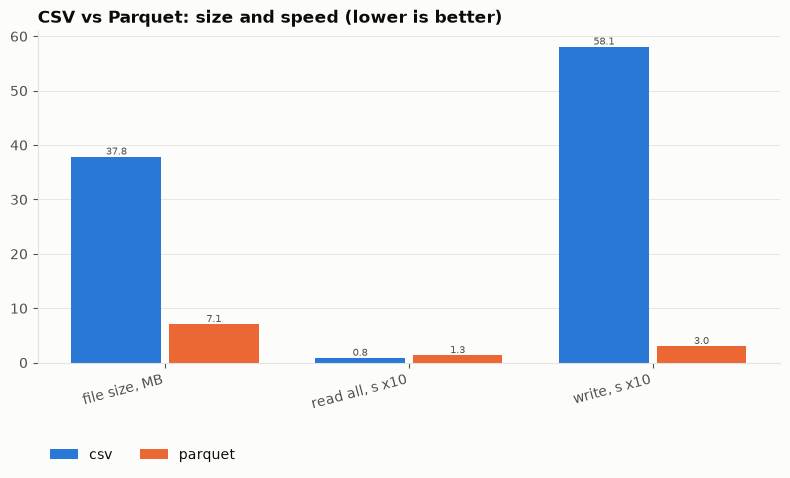

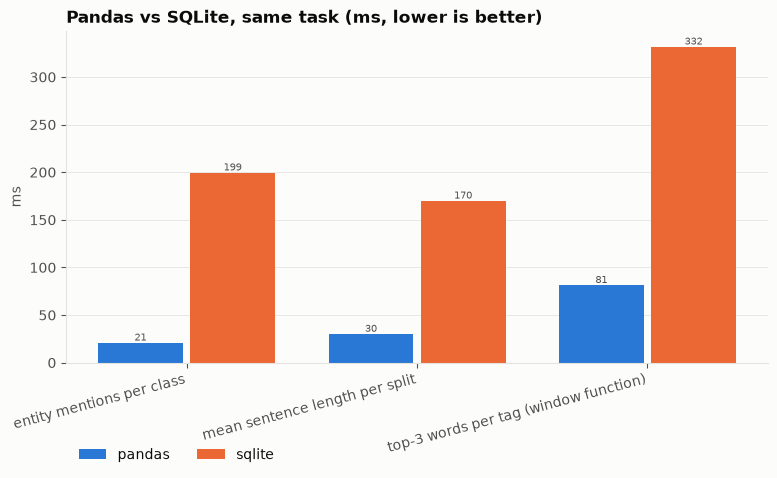

In [34]:
main_fmt = bench_fmt[bench_fmt["format"].isin(["csv", "parquet"])]
grouped_bars(["file size, MB", "read all, s x10", "write, s x10"],
             {r.format: [r.file_mb, r.read_all_s * 10, r.write_s * 10] for r in main_fmt.itertuples()},
             "CSV vs Parquet: size and speed (lower is better)", FIGURES_DIR / "bench_formats.png", fmt="{:.1f}")
p = bench_pvs.dropna(subset=["sqlite_s"])
grouped_bars(list(p["task"]), {"pandas": list(p["pandas_s"] * 1000), "sqlite": list(p["sqlite_s"] * 1000)},
             "Pandas vs SQLite, same task (ms, lower is better)",
             FIGURES_DIR / "bench_pandas_vs_sql.png", ylabel="ms", fmt="{:.0f}")

## 8. Error analysis and confusion matrix (best model)

In [35]:
print_header("8. Error analysis")
if not COMPARISON_CSV.exists():
    raise FileNotFoundError("No results yet — run section 5 first.")
best_name = pd.read_csv(COMPARISON_CSV).sort_values("f1_micro", ascending=False).iloc[0]["model"]
errors = pd.read_csv(RESULTS_DIR / f"errors_{best_name}.csv").fillna("—")
per_class = pd.read_csv(RESULTS_DIR / f"per_class_{best_name}.csv")
print(f"Model: {best_name}  ({len(errors):,} span errors on the test split)\n")
print(errors["error_type"].value_counts().rename("count").to_frame()
      .assign(share=lambda d: (d["count"] / d["count"].sum()).round(3)).to_string())
conf_err = errors[errors["error_type"].isin(["type_error", "type_and_boundary"])]
print("\nTop class confusions (gold -> predicted):")
print(conf_err.groupby(["gold_type", "pred_type"]).size().sort_values(ascending=False).head(10).to_string())
print("\nWeakest classes:")
print(per_class.sort_values("f1").head(8)[["entity_type", "precision", "recall", "f1", "support"]]
      .round(3).to_string(index=False))
print("\nExamples:")
for kind in ("missed", "spurious", "type_error", "boundary_error"):
    for r in errors[errors["error_type"] == kind].head(3).itertuples():
        print(f"  [{kind}] gold={r.gold_type}:{r.gold_text} | pred={r.pred_type}:{r.pred_text}\n"
              f"      … {r.context} …")


8. Error analysis
Model: crf  (1,162 span errors on the test split)

                   count  share
error_type                     
missed               357  0.307
boundary_error       257  0.221
type_and_boundary    232  0.200
type_error           209  0.180
spurious             107  0.092

Top class confusions (gold -> predicted):
gold_type     pred_type   
FACILITY      GPE             20
DATE          CARDINAL        18
ORGANISATION  GPE             18
GPE           PERSON          17
POSITION      ORGANISATION    17
CARDINAL      DATE            16
FACILITY      ORGANISATION    15
ORGANISATION  FACILITY        14
LOCATION      GPE             14
GPE           FACILITY        12

Weakest classes:
  entity_type  precision  recall    f1  support
    NON_HUMAN      0.000   0.000 0.000        1
        ADAGE      0.889   0.421 0.571       19
          LAW      0.659   0.527 0.586       55
     FACILITY      0.678   0.606 0.640      198
      PRODUCT      0.922   0.644 0.758       73


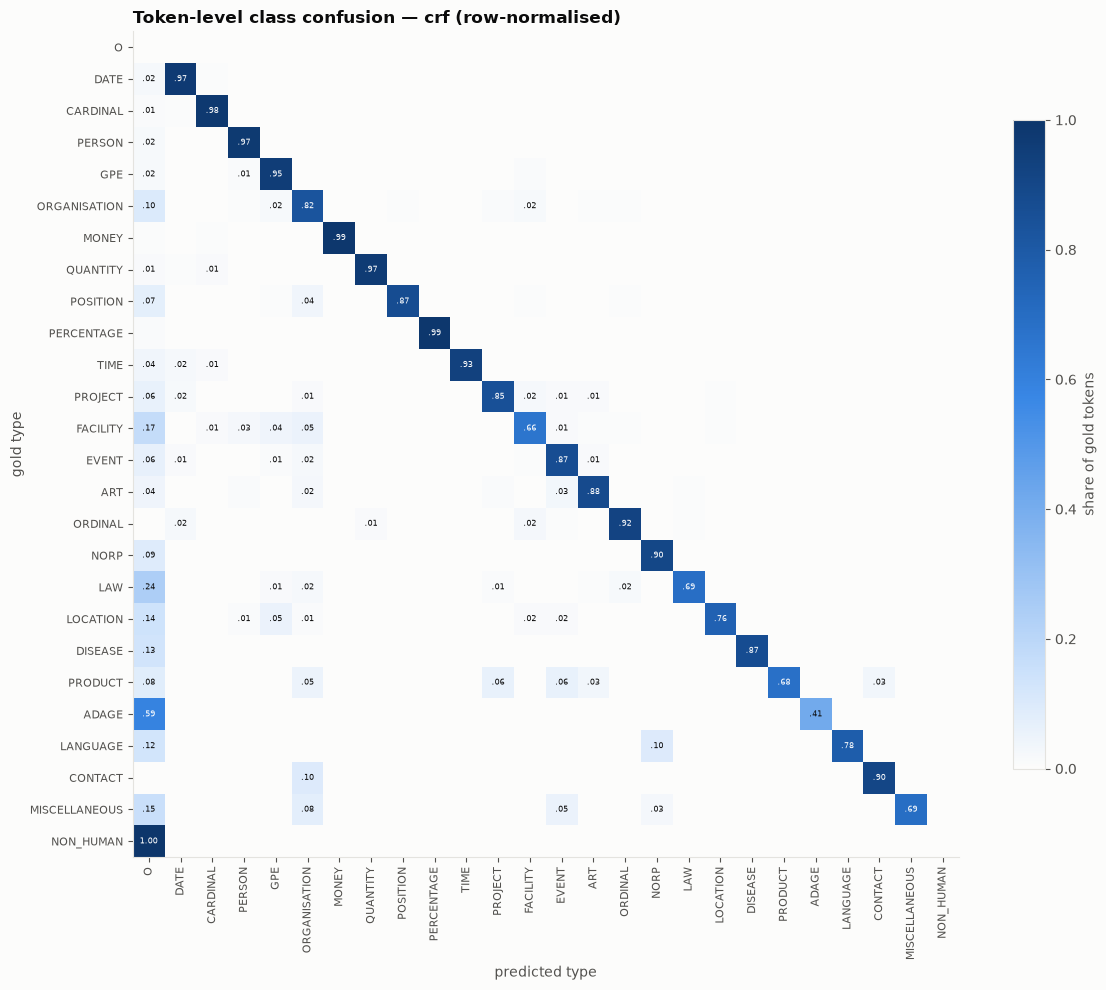

In [36]:
conf_mat = pd.read_csv(RESULTS_DIR / f"confusion_{best_name}.csv", index_col=0)
plot_confusion(conf_mat, f"Token-level class confusion — {best_name} (row-normalised)",
               FIGURES_DIR / f"confusion_{best_name}.png")

In [37]:
if best_name == "crf" or "crf" in TRAIN_MODELS:
    state, trans = load_model("crf").top_features(12)
    print("Strongest CRF state features:")
    for (attr, label), w in state:
        print(f"  {w:7.3f}  {label:<16} {attr}")
    print("Strongest CRF transitions:")
    for (a, b), w in trans[:8]:
        print(f"  {w:7.3f}  {a} -> {b}")

Strongest CRF state features:
    7.567  B-DATE           pre3:бүг
    7.038  B-POSITION       pre3:елб
    6.798  B-DATE           pre3:биы
    6.677  B-DISEASE        stem:коронавирус
    6.619  B-CARDINAL       pre3:үше
    6.299  I-TIME           pre3:сағ
    6.141  I-DATE           -1:w|w:бүгінгі|күні
    5.988  B-DATE           stem:көктем
    5.804  I-PERCENTAGE     pre3:пай
    5.802  B-POSITION       pre3:пре
    5.716  I-GPE            pre3:обл
    5.538  I-PERCENTAGE     pre3:про
Strongest CRF transitions:
    8.898  B-PERCENTAGE -> I-PERCENTAGE
    8.371  B-MONEY -> I-MONEY
    8.353  B-EVENT -> I-EVENT
    8.195  B-QUANTITY -> I-QUANTITY
    8.078  B-PERSON -> I-PERSON
    8.045  I-EVENT -> I-EVENT
    7.916  B-FACILITY -> I-FACILITY
    7.871  B-ART -> I-ART


## 9. Recognising entities in your own text
Each query and its entities are saved to the `user_queries` / `user_query_entities` tables and appended to
`reports/results/user_predictions.csv`.

In [38]:
def available_models():
    """Locally trained models plus the fine-tuned transformer, if its folder exists."""
    names = [p.stem for p in sorted(MODELS_DIR.glob("*.joblib"))]
    if (MODELS_DIR / "transformer" / "config.json").exists():
        names.append("transformer")
    return names


def best_model_name():
    """Model with the highest test F1 in model_comparison.csv that is available on disk."""
    avail = available_models()
    if COMPARISON_CSV.exists():
        table = pd.read_csv(COMPARISON_CSV).sort_values("f1_micro", ascending=False)
        for name in table["model"]:
            if name in avail:
                return name
    if not avail:
        raise FileNotFoundError("No trained model found — run section 5 first.")
    return "crf" if "crf" in avail else avail[0]


def get_tagger(name):
    if name == "transformer":
        return TransformerTagger(MODELS_DIR / "transformer")   # defined in section 11
    return load_model(name)


def predict_text(text, tagger):
    """Split into sentences, tokenize, tag. Returns list of {sentence, type, text, start, end}."""
    entities = []
    for k, sentence in enumerate(split_sentences(text)):
        tokens = tokenize(sentence)
        if not tokens:
            continue
        tags = tagger.predict([tokens])[0]
        for etype, s, e in get_spans(tags):
            entities.append({"sentence": k, "type": etype, "text": span_text(tokens, s, e),
                             "start": s, "end": e, "description": ENTITY_TYPES.get(etype, "")})
    return entities


def highlight(text, tagger):
    """Inline view: tokens of each entity wrapped as [text](TYPE)."""
    out = []
    for sentence in split_sentences(text):
        tokens = tokenize(sentence)
        tags = tagger.predict([tokens])[0] if tokens else []
        spans = {s: (etype, e) for etype, s, e in get_spans(tags)}
        i, parts = 0, []
        while i < len(tokens):
            if i in spans:
                etype, e = spans[i]
                parts.append(f"[{span_text(tokens, i, e)}]({etype})")
                i = e
            else:
                parts.append(tokens[i])
                i += 1
        out.append(" ".join(parts))
    return " ".join(out)


def save_session(rows, path=None):
    """Append the session's results to a CSV file (persistent storage of user queries)."""
    path = Path(path or RESULTS_DIR / "user_predictions.csv")
    pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)
    return path


def recognise(text, model_name=None, tagger=None, save=True):
    """Tag `text`, print the highlighted version, store the query; returns the entities as a DataFrame."""
    model_name = model_name or best_model_name()
    tagger = tagger or get_tagger(model_name)
    entities = predict_text(text, tagger)
    print(highlight(text, tagger))
    if save:
        conn = connect()
        try:
            log_user_query(conn, model_name, text, entities)
        except sqlite3.Error as exc:
            print(f"(not saved to the database: {exc})")
        finally:
            conn.close()
        if entities:
            save_session([{"model": model_name, "input": text, **e} for e in entities])
    return pd.DataFrame(entities, columns=["sentence", "type", "text", "start", "end", "description"])

In [39]:
print("Available models:", available_models(), "| best:", best_model_name())
MODEL_NAME = best_model_name()          # or e.g. "sgd_tfidf"
tagger = get_tagger(MODEL_NAME)
recognise("Қасым-Жомарт Тоқаев 2024 жылғы 15 наурызда Астанада Ұлттық банктің төрағасы "
          "Тимур Сүлейменовпен кездесті.", MODEL_NAME, tagger)

Available models: ['baseline_lookup', 'crf', 'sgd_bow', 'sgd_tfidf', 'sgd_word2vec'] | best: crf
[Қасым-Жомарт Тоқаев](PERSON) [2024 жылғы 15 наурызда](DATE) [Астанада](GPE) [Ұлттық банктің](ORGANISATION) төрағасы [Тимур Сүлейменовпен](PERSON) кездесті .


,sentence,type,text,start,end,description
0,0,PERSON,Қасым-Жомарт Тоқаев,0,2,"People, including fictional"
1,0,DATE,2024 жылғы 15 наурызда,2,6,Absolute or relative dates and periods
2,0,GPE,Астанада,6,7,"Geo-political entities: countries, cities, regions"
3,0,ORGANISATION,Ұлттық банктің,7,9,"Companies, agencies, institutions"
4,0,PERSON,Тимур Сүлейменовпен,10,12,"People, including fictional"


In [ ]:
# Interactive mode: type Kazakh text, an empty line stops the loop
while True:
    text = input("Text> ").strip()
    if not text:
        break
    display(recognise(text, MODEL_NAME, tagger))

## 10. Results summary

In [41]:
summary = pd.read_csv(COMPARISON_CSV).sort_values("f1_micro", ascending=False)
cols = ["model", "f1_micro", "f1_macro", "precision_micro", "recall_micro", "accuracy",
        "train_time_s", "predict_time_s", "peak_mem_mb", "train_sentences"]
summary[cols].round(4)

,model,f1_micro,f1_macro,precision_micro,recall_micro,accuracy,train_time_s,predict_time_s,peak_mem_mb,train_sentences
4,crf,0.9312,0.8234,0.9408,0.9219,0.9825,628.6433,3.8441,1098.0000,90228
2,sgd_tfidf,0.6128,0.3715,0.5828,0.6461,0.9301,25.0949,2.1175,532.7070,30000
3,sgd_word2vec,0.6053,0.3726,0.6081,0.6025,0.9272,71.8228,2.2163,1365.0391,30000
1,sgd_bow,0.6026,0.3787,0.5975,0.6079,0.9277,18.2284,1.7628,539.9688,30000
0,baseline_lookup,0.4925,0.3995,0.4207,0.5939,0.9112,0.9080,0.0180,2.8984,90228


## 11. *(Optional, GPU)* Fine-tuning XLM-RoBERTa

Set `RUN_TRANSFORMER = True` in section 0. The model is fine-tuned on train, the best epoch is chosen on
valid, and it is evaluated on test. Its scores, predictions and errors go into the same CSV files and SQLite
tables as the other models, so sections 6, 8, 9 and 10 pick it up when re-run. The published XLM-RoBERTa
result on KazNERD is F1 = 0.9722.

For a CPU smoke test without internet, build a tiny random BERT in the last cell and set
`TRANSFORMER_ARGS["model"] = str(MODELS_DIR / "tiny_bert")`.

In [42]:
LABEL_PAD = -100

TRANSFORMER_ARGS = {
    "model": "xlm-roberta-base",     # or "xlm-roberta-large" (>= 16 GB GPU: batch_size 8, lr 2e-5)
    "epochs": 3,
    "batch_size": 16,
    "lr": 3e-5,
    "max_length": 256,
    "max_train_sentences": None,     # subsample train (quick runs)
    "max_eval_sentences": None,      # truncate valid/test (smoke tests only)
    "workers": 0,
    "no_fp16": False,
}


def build_label_list(sents):
    labels = sorted({t for _, _, tags in sents for t in tags} - {"O"})
    return ["O"] + labels


class NERDataset:
    """Tokenizes pre-split words and aligns IOB2 labels to the first sub-token of each word."""

    def __init__(self, sents, tokenizer, label2id, max_length=256):
        self.items = []
        for _, tokens, tags in sents:
            enc = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=max_length)
            labels, prev = [], None
            for wid in enc.word_ids():
                if wid is None or wid == prev:
                    labels.append(LABEL_PAD)
                else:
                    labels.append(label2id[tags[wid]])
                prev = wid
            enc["labels"] = labels
            self.items.append(dict(enc))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        return self.items[i]


class TransformerTagger:
    """Inference wrapper with the same predict(token_lists) interface as the other models."""

    name = "transformer"

    def __init__(self, model_dir, batch_size=32, max_length=256, device=None):
        import torch
        from transformers import AutoModelForTokenClassification, AutoTokenizer
        self.torch = torch
        self.tokenizer = AutoTokenizer.from_pretrained(model_dir)
        self.model = AutoModelForTokenClassification.from_pretrained(model_dir)
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model.to(self.device).eval()
        self.id2label = {int(k): v for k, v in self.model.config.id2label.items()}
        self.batch_size, self.max_length = batch_size, max_length
        self.description = f"Fine-tuned {self.model.config.name_or_path or 'transformer'}"

    def predict(self, token_lists):
        out = []
        for b in range(0, len(token_lists), self.batch_size):
            batch = token_lists[b:b + self.batch_size]
            non_empty = [t if t else ["."] for t in batch]
            enc = self.tokenizer(non_empty, is_split_into_words=True, truncation=True,
                                 max_length=self.max_length, padding=True, return_tensors="pt")
            with self.torch.no_grad():
                logits = self.model(**{k: v.to(self.device) for k, v in enc.items()}).logits
            pred_ids = logits.argmax(-1).cpu().numpy()
            for k, tokens in enumerate(batch):
                tags = ["O"] * len(tokens)
                seen = set()
                for pos, wid in enumerate(enc.word_ids(k)):
                    if wid is not None and wid not in seen and wid < len(tokens):
                        tags[wid] = self.id2label[int(pred_ids[k, pos])]
                        seen.add(wid)
                out.append(tags)
        return out


def train_transformer(args):
    import torch
    from transformers import (AutoModelForTokenClassification, AutoTokenizer,
                              DataCollatorForTokenClassification, Trainer, TrainingArguments)

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    train_s, valid_s, test_s = sentences["train"], sentences["valid"], sentences["test"]
    if args["max_train_sentences"]:
        train_s = random.Random(SEED).sample(train_s, min(args["max_train_sentences"], len(train_s)))
    if args["max_eval_sentences"]:
        valid_s = valid_s[:args["max_eval_sentences"]]
        test_s = test_s[:args["max_eval_sentences"]]

    labels = build_label_list(sentences["train"])
    label2id = {l: i for i, l in enumerate(labels)}
    id2label = dict(enumerate(labels))

    tokenizer = AutoTokenizer.from_pretrained(args["model"])
    model = AutoModelForTokenClassification.from_pretrained(
        args["model"], num_labels=len(labels), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)   # allows starting from a checkpoint with another label set

    train_ds = NERDataset(train_s, tokenizer, label2id, args["max_length"])
    valid_ds = NERDataset(valid_s, tokenizer, label2id, args["max_length"])

    def compute_metrics(eval_pred):
        logits, gold = eval_pred
        pred = logits.argmax(-1)
        y_true, y_pred = [], []
        for p_row, g_row in zip(pred, gold):
            keep = g_row != LABEL_PAD
            y_true.append([id2label[int(i)] for i in g_row[keep]])
            y_pred.append([id2label[int(i)] for i in p_row[keep]])
        return {"f1": f1_score(y_true, y_pred)}

    ckpt_dir = MODELS_DIR / "transformer_checkpoints"
    total_steps = int(np.ceil(len(train_ds) / args["batch_size"]) * args["epochs"])
    warmup_steps = int(0.1 * total_steps)       # 10 % linear warm-up
    training_args = TrainingArguments(
        output_dir=str(ckpt_dir), learning_rate=args["lr"], num_train_epochs=args["epochs"],
        per_device_train_batch_size=args["batch_size"], per_device_eval_batch_size=args["batch_size"] * 2,
        weight_decay=0.01, warmup_steps=warmup_steps, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1", save_total_limit=1,
        logging_steps=200, fp16=torch.cuda.is_available() and not args["no_fp16"],
        report_to="none", seed=SEED, dataloader_num_workers=args["workers"],
    )
    trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=valid_ds,
                      data_collator=DataCollatorForTokenClassification(tokenizer),
                      processing_class=tokenizer, compute_metrics=compute_metrics)
    with ResourceMonitor() as mon:
        trainer.train()
    out_dir = MODELS_DIR / "transformer"
    trainer.save_model(str(out_dir))
    tokenizer.save_pretrained(str(out_dir))
    gpu_mb = torch.cuda.max_memory_allocated() / 2 ** 20 if torch.cuda.is_available() else None
    print(f"Training done in {mon.seconds / 60:.1f} min; model saved to {out_dir}")

    tagger = TransformerTagger(out_dir, batch_size=args["batch_size"] * 2, max_length=args["max_length"])
    tagger.description = f"Fine-tuned {args['model']} ({args['epochs']} epochs, lr {args['lr']})"
    info = {"train_sentences": len(train_s), "n_features": sum(p.numel() for p in model.parameters()),
            "train_time_s": mon.seconds, "peak_mem_mb": gpu_mb if gpu_mb is not None else mon.peak_mb}
    return evaluate_and_record(tagger, test_s, info)

In [43]:
if RUN_TRANSFORMER:
    train_transformer(TRANSFORMER_ARGS)
else:
    print("Skipped (RUN_TRANSFORMER = False).")

Skipped (RUN_TRANSFORMER = False).


In [44]:
def make_tiny_model(vocab_size=8000, n_sentences=30000):
    """Tiny, randomly initialised BERT + WordPiece tokenizer built from KazNERD.

    NOT a useful NER model: it only smoke-tests the fine-tuning code path
    (sub-word label alignment, training, evaluation, saving, inference) without internet or GPU.
    The smoke run overwrites the 'transformer' row in the results — delete models/transformer afterwards.
    """
    from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, processors, trainers
    from transformers import BertConfig, BertForTokenClassification, PreTrainedTokenizerFast

    target = MODELS_DIR / "tiny_bert"
    target.mkdir(parents=True, exist_ok=True)
    ensure_raw_data()
    corpus = [" ".join(t) for t, _ in read_conll(RAW_DIR / "IOB2_train.txt")][:n_sentences]

    tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
    tok.normalizer = normalizers.Lowercase()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(corpus, trainers.WordPieceTrainer(
        vocab_size=vocab_size, special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]))
    tok.post_processor = processors.TemplateProcessing(
        single="[CLS] $A [SEP]", special_tokens=[("[CLS]", 2), ("[SEP]", 3)])
    fast = PreTrainedTokenizerFast(tokenizer_object=tok, unk_token="[UNK]", pad_token="[PAD]",
                                   cls_token="[CLS]", sep_token="[SEP]", mask_token="[MASK]")
    fast.save_pretrained(str(target))

    cfg = BertConfig(vocab_size=vocab_size, hidden_size=64, num_hidden_layers=2,
                     num_attention_heads=2, intermediate_size=128, max_position_embeddings=512)
    BertForTokenClassification(cfg).save_pretrained(str(target))
    print(f"Tiny model saved to {target}")

# Smoke test (uncomment):
# make_tiny_model()
# train_transformer({**TRANSFORMER_ARGS, "model": str(MODELS_DIR / "tiny_bert"), "epochs": 1,
#                    "max_train_sentences": 2000, "max_eval_sentences": 500})